# Vinheria Agnello — Fase 3
## Modelagem de Aprendizado Supervisionado com Árvore de Decisão

### 1. Introdução

A Vinheria Agnello busca compreender o comportamento de seus consumidores e apoiar
suas decisões comerciais. Nesta etapa de Ciência de Dados, investigamos se os dados
de uma tentativa de compra permitem antecipar sua conclusão. Trata-se de um problema
de **classificação supervisionada binária**: aprendemos com tentativas cujo resultado
já é conhecido para estimar o resultado de novas tentativas.

A variável alvo é `did_costumer_finish_sale`: **0 = compra não finalizada** e
**1 = compra finalizada**. O problema de negócio é identificar tentativas com risco
de não conclusão, que poderiam orientar uma abordagem de atendimento ou uma futura
funcionalidade do Sommelier Virtual. Valor comercial depende de desempenho fora da
amostra, custos de intervenção e validação com clientes reais; não decorre apenas
da obtenção de uma boa acurácia.

**Momento da previsão:** imediatamente antes da finalização, quando o cadastro,
o produto, o preço e o desconto já estão disponíveis. Assume-se que os campos
cadastrais representam o estado nesse momento. O CSV não fornece histórico de
atualizações para comprovar essa premissa.

Este relatório executável utiliza somente o CSV fornecido, conserva seus nomes
originais (inclusive a grafia `costumer`) e não altera a fonte. Cada linha é tratada
como uma tentativa associada a um produto. Como não há identificador de carrinho,
não podemos assegurar que tentativas de produtos diferentes sejam carrinhos distintos.

**Fontes locais:** [enunciado](../05_Referencias/ENUNCIADO_FASE3.txt),
[notas do grupo](../05_Referencias/NOTAS_FELIPE.txt) e
[CSV oficial](../01_Dados/dataset_vinheria_agnello.csv) e
[XLSX de referência](../01_Dados/dataset_vinheria_agnello.xlsx).
Somente o CSV oficial alimenta a modelagem.
Os arquivos em `01_Dados` são idênticos aos arquivos definitivos recebidos.
O escopo deste arquivo é a modelagem; PDF, dashboard e screenshots são outras
partes da entrega e não são produzidos aqui.

### 2. Importação das bibliotecas

Usamos pandas e NumPy para análise, matplotlib para gráficos e scikit-learn para
pré-processamento, divisão por grupos, treinamento e avaliação. IPython permite
apresentar tabelas e interpretações calculadas dentro do próprio notebook.
O ambiente deve ter Python 3.10+ e essas bibliotecas instaladas. A tabela abaixo
registra as versões efetivamente utilizadas na execução, sem instalar nada pelo notebook.

In [1]:
from pathlib import Path
from hashlib import sha256
from importlib.metadata import version
import sys
from zipfile import ZipFile
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import (
    GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
)

%matplotlib inline

SEED = 42
# Data fixa de referência da auditoria; evita resultados diferentes em outra execução.
DATA_REFERENCIA = pd.Timestamp('2026-11-04')
NOMES_CLASSES = ['Não finalizada (0)', 'Finalizada (1)']
CORES = ['#315B78', '#8C2946']
plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 120,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
})
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

versoes = {'Python': sys.version.split()[0]}
versoes.update({p: version(p) for p in ['pandas', 'numpy', 'matplotlib', 'scikit-learn']})
display(pd.Series(versoes, name='Versão').to_frame())
print('Semente para operações aleatórias:', SEED)

,Versão
Python,3.12.14
pandas,2.2.3
numpy,2.3.5
matplotlib,3.11.2
scikit-learn,1.9.1


Semente para operações aleatórias: 42


### 3. Carregamento e reconhecimento da base

O caminho **exclusivo da pasta `01_Dados`** é resolvido a partir da pasta atual e de suas pastas superiores, permitindo
executar o notebook tanto em `02_Modelagem` quanto na raiz do projeto. A leitura usa
UTF-8 com tratamento do BOM. O hash SHA-256 identifica a versão da fonte e será
recalculado no final para verificar que o CSV permaneceu intacto.

Exibimos os primeiros cinco registros, dimensões, nomes e tipos inferidos. CSV não
armazena tipos formalmente: datas são inicialmente texto e IDs inteiros são
identificadores nominais, não medidas quantitativas.

#### Fonte oficial da entrega

A base oficial contém 999 registros e 16 colunas. O alvo apresenta 619
compras finalizadas (61,96%) e 380 não finalizadas (38,04%). Os arquivos
definitivos estão diretamente em `01_Dados/`; todos os resultados deste
notebook utilizam exclusivamente o CSV identificado pelo hash abaixo.

O XLSX é inspecionado sem recalcular suas fórmulas. Seus valores salvos diferem do
CSV e há fórmulas aleatórias para atributos e alvo. Portanto, não será usado para
preencher, combinar ou substituir registros do CSV oficial.


In [2]:
pastas = [Path.cwd(), *Path.cwd().parents]
candidatos = [
    pasta / caminho
    for pasta in pastas
    for caminho in [
        Path('01_Dados/dataset_vinheria_agnello.csv'),
        Path('Fase3_DataScience/01_Dados/dataset_vinheria_agnello.csv'),
    ]
]
CSV_PATH = next((p.resolve() for p in candidatos if p.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError('Execute a partir do projeto ou da pasta 02_Modelagem.')

HASH_OFICIAL_ESPERADO = '39897f7a1648eed5bb3a58b36a5a131dd67fdf96a190596f36a8ee14bf91a4e1'
HASH_ORIGINAL = sha256(CSV_PATH.read_bytes()).hexdigest()
assert HASH_ORIGINAL == HASH_OFICIAL_ESPERADO, 'Fonte diferente da versão oficial auditada.'
df = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
ALVO = 'did_costumer_finish_sale'
COLUNAS_ESPERADAS = [
    'costumer_id', 'costumer_profile', 'costumer_country', 'costumer_age',
    'costumer_days_since_last_sale', 'is_costumer_afiliated', 'used_virtual_sommelier', 'product_id',
    'product_label', 'product_category', 'price', 'discount_percentage',
    'final_price', 'product_review_score', 'date', ALVO,
]
assert df.columns.tolist() == COLUNAS_ESPERADAS
assert df.shape == (999, 16), 'A fonte mudou: revisar as interpretações documentadas.'
assert set(df[ALVO].unique()) == {0, 1}

print('Fonte:', CSV_PATH)
print('SHA-256:', HASH_ORIGINAL)
print(f'Dimensões: {df.shape[0]} linhas × {df.shape[1]} colunas')
display(df.head())
display(pd.DataFrame({
    'Coluna exatamente como no CSV': df.columns,
    'Tipo inferido': df.dtypes.astype(str).values,
}))

# Inspeção isolada da referência: ler XML e valores salvos, sem motor de cálculo.
XLSX_PATH = CSV_PATH.with_suffix('.xlsx')
if XLSX_PATH.is_file():
    ns = {'x': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with ZipFile(XLSX_PATH) as arquivo_xlsx:
        folha_xml = ET.fromstring(arquivo_xlsx.read('xl/worksheets/sheet1.xml'))
        celulas_xml = {c.get('r'): c for c in folha_xml.findall('.//x:sheetData/x:row/x:c', ns)}
        formulas_referencia = {}
        for endereco in ['G2', 'P2']:
            formula = celulas_xml[endereco].find('x:f', ns)
            formulas_referencia[endereco] = formula.text if formula is not None else '(sem fórmula)'
        alvo_salvo_xlsx = [
            int(c.find('x:v', ns).text)
            for endereco, c in celulas_xml.items()
            if endereco.startswith('P') and endereco != 'P1'
            and c.find('x:v', ns) is not None
        ]
    display(pd.Series(formulas_referencia, name='Fórmula consultada no XLSX').to_frame())
    auditoria_fontes = pd.DataFrame({
        'CSV oficial': df[ALVO].value_counts().reindex([0, 1], fill_value=0),
        'XLSX — valores salvos (somente inspeção)': pd.Series(alvo_salvo_xlsx).value_counts().reindex([0, 1], fill_value=0),
    })
    display(auditoria_fontes.rename_axis('Classe'))
    print('XLSX possui fórmulas e valores diferentes; somente o CSV alimenta X e y.')
else:
    print('XLSX ausente neste ambiente; ele não é necessário para treinar o modelo.')


Fonte: /Users/jp/Dev/Facul/VinheriaAgnello/Fase3_DataScience/01_Dados/dataset_vinheria_agnello.csv
SHA-256: 39897f7a1648eed5bb3a58b36a5a131dd67fdf96a190596f36a8ee14bf91a4e1
Dimensões: 999 linhas × 16 colunas


,costumer_id,costumer_profile,costumer_country,costumer_age,costumer_days_since_last_sale,is_costumer_afiliated,used_virtual_sommelier,product_id,product_label,product_category,price,discount_percentage,final_price,product_review_score,date,did_costumer_finish_sale
0,1,sommelier,brazil,30,28,False,False,2,Syrah 2023,branco,700,38,434.0,4.8,9/5/2026,0
1,79,sommelier,brazil,43,22,False,True,6,Canindé 2024,branco,600,0,600.0,3.9,1/11/2026,1
2,125,curious_costumer,brazil,49,20,False,True,7,Inanna Alvarinho 2023,rose,650,38,403.0,4.5,9/21/2025,0
3,67,invested_costumer,brazil,37,27,False,False,8,Bianco Macerato 2016,tinto,800,0,800.0,4.2,8/2/2025,1
4,142,invested_costumer,brazil,22,83,False,True,4,TF Terroir Chardonnay 2023,tinto,1500,0,1500.0,5.0,8/27/2025,1


,Coluna exatamente como no CSV,Tipo inferido
0,costumer_id,int64
1,costumer_profile,object
2,costumer_country,object
3,costumer_age,int64
4,costumer_days_since_last_sale,int64
5,is_costumer_afiliated,bool
6,used_virtual_sommelier,bool
7,product_id,int64
8,product_label,object
9,product_category,object


,Fórmula consultada no XLSX
G2,"IF(RANDBETWEEN(0, 100) > 40, FALSE, TRUE)"
P2,"IF(RANDBETWEEN(0, 100) > 36, 1, 0)"


,CSV oficial,XLSX — valores salvos (somente inspeção)
Classe,,
0,380,378
1,619,621


XLSX possui fórmulas e valores diferentes; somente o CSV alimenta X e y.


### 4. Análise exploratória inicial

A base contém **999 registros**. As classes apresentam desbalanceamento moderado:
619 compras finalizadas (61,96%) e 380 não finalizadas (38,04%). Os cálculos abaixo
conferem esses números a partir do arquivo, sem preencher ou remover registros.

Verificamos ausências, campos vazios, duplicação integral, cardinalidade e estatísticas
descritivas. Repetir um cliente em outra tentativa não significa duplicar a linha.
O gráfico de contagens mostra a composição das classes e motiva o uso de métricas
que deem atenção à classe minoritária.

A exploração global é descritiva. Nenhuma seleção de features ou hiperparâmetros
será feita buscando melhorar o resultado do teste; a lista de entradas já foi
definida antes da modelagem.

,Tipo,Ausentes,Vazios ou só espaços,Valores únicos
costumer_id,int64,0,0,180
costumer_profile,object,0,0,4
costumer_country,object,0,0,5
costumer_age,int64,0,0,52
costumer_days_since_last_sale,int64,0,0,81
is_costumer_afiliated,bool,0,0,2
used_virtual_sommelier,bool,0,0,2
product_id,int64,0,0,8
product_label,object,0,0,8
product_category,object,0,0,3


Registros integralmente duplicados: 0
Duplicados desconsiderando apenas costumer_id: 0


,count,mean,std,min,25%,50%,75%,max
costumer_id,999.0,88.9249,51.1245,0.0,45.0,87.0,132.0,180.0
costumer_age,999.0,46.1351,14.7085,21.0,34.0,46.0,59.0,72.0
costumer_days_since_last_sale,999.0,50.2272,23.5597,10.0,29.0,51.0,71.0,90.0
product_id,999.0,4.3504,2.2640,1.0,2.0,4.0,6.0,8.0
price,999.0,692.5425,393.8517,200.0,290.0,650.0,800.0,1500.0
discount_percentage,999.0,14.3463,18.0382,0.0,0.0,0.0,32.0,50.0
final_price,999.0,591.9358,360.3856,100.0,290.0,600.0,800.0,1500.0
product_review_score,999.0,4.2144,0.5519,3.2,3.9,4.2,4.8,5.0
did_costumer_finish_sale,999.0,0.6196,0.4857,0.0,0.0,1.0,1.0,1.0


,count,unique,top,freq
costumer_profile,999,4,curious_costumer,263
costumer_country,999,5,brazil,686
is_costumer_afiliated,999,2,False,696
used_virtual_sommelier,999,2,False,571
product_label,999,8,Cabernet Sauvignon 2005,145
product_category,999,3,tinto,527
date,999,645,12/10/2024,5


,Resultado,Quantidade,Porcentagem (%)
Classe,,,
0,Não finalizada (0),380,38.038
1,Finalizada (1),619,61.962


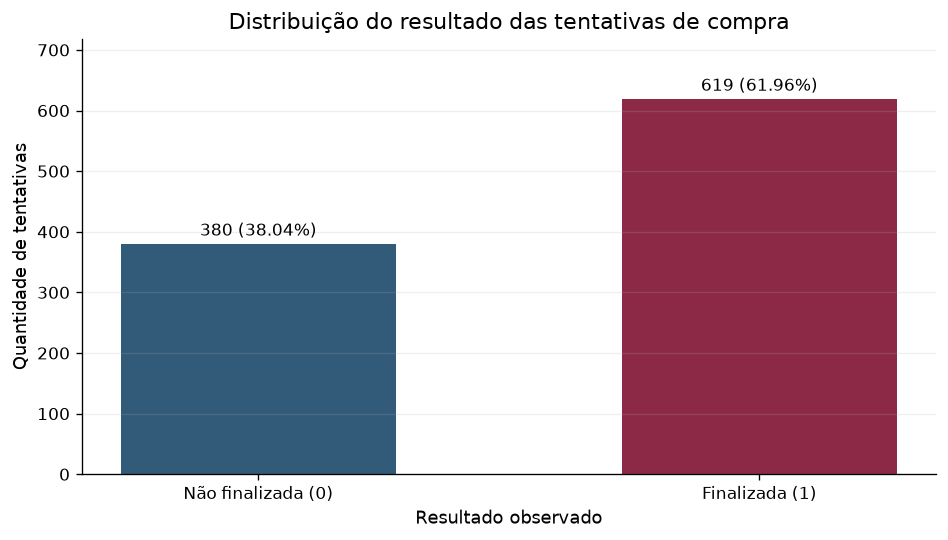

In [3]:
qualidade = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'Ausentes': df.isna().sum(),
    'Vazios ou só espaços': df.apply(lambda s: s.astype(str).str.strip().eq('').sum()),
    'Valores únicos': df.nunique(dropna=False),
})
display(qualidade)
print('Registros integralmente duplicados:', int(df.duplicated().sum()))
print('Duplicados desconsiderando apenas costumer_id:',
      int(df.drop(columns='costumer_id').duplicated().sum()))
display(df.describe().T)
display(df.select_dtypes(include=['object', 'bool']).describe().T)

contagens = df[ALVO].value_counts().reindex([0, 1], fill_value=0)
distribuicao = pd.DataFrame({
    'Resultado': NOMES_CLASSES,
    'Quantidade': contagens.to_numpy(),
    'Porcentagem (%)': contagens.to_numpy() / len(df) * 100,
}, index=pd.Index([0, 1], name='Classe'))
display(distribuicao)

fig, ax = plt.subplots(figsize=(8, 4.6))
barras = ax.bar(NOMES_CLASSES, contagens, color=CORES, width=0.55)
for barra, n in zip(barras, contagens):
    ax.annotate(f'{n} ({n / len(df):.2%})',
                (barra.get_x() + barra.get_width() / 2, n),
                xytext=(0, 5), textcoords='offset points', ha='center')
ax.set(title='Distribuição do resultado das tentativas de compra',
       xlabel='Resultado observado', ylabel='Quantidade de tentativas', ylim=(0, contagens.max() * 1.16))
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

### 5. Limitações e qualidade dos dados

A ausência de nulos e duplicados não garante consistência semântica. A auditoria
anterior identificou os pontos abaixo, novamente verificados na execução:

- **Idades inconsistentes por ID:** o mesmo identificador apresenta idades
  incompatíveis com a passagem de tempo de 2024 a 2026. Agrupar pelo ID é uma
  precaução metodológica, mas não comprova que ele represente uma pessoa real.
- **Novos clientes com recência:** todos os registros `new_costumer` possuem dias
  desde a última venda. O significado desse perfil precisaria ser esclarecido.
- **Datas futuras:** há eventos posteriores à referência fixa de 04/11/2026.
  Não são removidos, pois a fonte é declaradamente simulada. Isso impede tratar
  os registros como vendas reais já observadas naquela data.
- **Dependência entre atributos de produto:** nome, categoria, preço e nota são
  fixos para cada um dos oito produtos. Nesta amostra, cada preço identifica um
  produto, podendo funcionar como um identificador indireto.
- **Preço final derivado:** `final_price = price × (1 − discount_percentage / 100)`.
  Isso é redundância, não evidência automática de leakage do alvo.
- **Clientes repetidos:** várias tentativas compartilham o mesmo ID; por isso,
  separaremos grupos completos entre treino e teste.
- **Risco temporal:** não sabemos se recência e avaliação foram calculadas com
  informações disponíveis antes da tentativa. Ficam fora do primeiro modelo.
- **Texto:** existe um espaço não separável antes de um nome de produto.
  Como esse campo não entra no modelo, não há necessidade de normalizá-lo aqui.

Não alteraremos idades, perfis, categorias ou datas para produzir uma aparência
artificial de consistência. Essas limitações serão consideradas na conclusão.

**Referência da simulação:** no XLSX, a fórmula consultada para o alvo usa um sorteio
(`IF(RANDBETWEEN(0, 100) > 36, 1, 0)`), sem referência aos atributos, e o indicador
de Sommelier usa outro sorteio. Isso é compatível com baixo sinal preditivo e
ausência de comportamento real de usuários. Como os valores salvos no XLSX diferem
do CSV, essa inspeção documenta a referência de geração; não prova a procedência
linha a linha do CSV nem permite reconstituí-lo. O notebook não recalcula a planilha.


In [4]:
datas = pd.to_datetime(df['date'], format='%m/%d/%Y', errors='coerce')
idades_por_id = df.groupby('costumer_id')['costumer_age'].agg(['min', 'max', 'nunique'])
frequencia_ids = df['costumer_id'].value_counts()
novos = df.loc[df['costumer_profile'].eq('new_costumer')]
preco_calculado = df['price'] * (1 - df['discount_percentage'] / 100)
erro_preco = (df['final_price'] - preco_calculado).abs()

auditoria = pd.DataFrame([
    ['IDs distintos', df['costumer_id'].nunique(), 'Não equivalem a pessoas confirmadas'],
    ['IDs com mais de uma tentativa', frequencia_ids.gt(1).sum(), 'Separar por grupos'],
    ['IDs com mais de uma idade', idades_por_id['nunique'].gt(1).sum(), 'Inconsistência cadastral'],
    ['Registros new_costumer com recência positiva',
     novos['costumer_days_since_last_sale'].gt(0).sum(), 'Rever definição do perfil'],
    ['Datas posteriores a 04/11/2026', datas.gt(DATA_REFERENCIA).sum(), 'Simulação'],
    ['Datas não interpretáveis', datas.isna().sum(), 'Formato mês/dia/ano'],
    ['Produtos distintos', df['product_id'].nunique(), 'Catálogo pequeno'],
    ['Linhas com preço final coerente',
     np.isclose(df['final_price'], preco_calculado).sum(), 'Relação determinística'],
], columns=['Verificação', 'Quantidade', 'Interpretação'])
display(auditoria)
print(f'Período: {datas.min():%d/%m/%Y} a {datas.max():%d/%m/%Y}')
print(f'Maior erro absoluto da fórmula de preço: {erro_preco.max():.3e}')
display(df.loc[df['costumer_id'].eq(108),
               ['costumer_id', 'costumer_age', 'costumer_country', 'date']])
print('Valores distintos por produto (1 indica atributo fixo):')
display(df.groupby('product_id')[[
    'product_label', 'product_category', 'price', 'product_review_score',
]].nunique())
print('Nomes de produto com espaço nas extremidades:',
      [repr(v) for v in df['product_label'].unique() if v != v.strip()])

,Verificação,Quantidade,Interpretação
0,IDs distintos,180,Não equivalem a pessoas confirmadas
1,IDs com mais de uma tentativa,177,Separar por grupos
2,IDs com mais de uma idade,177,Inconsistência cadastral
3,Registros new_costumer com recência positiva,238,Rever definição do perfil
4,Datas posteriores a 04/11/2026,40,Simulação
5,Datas não interpretáveis,0,Formato mês/dia/ano
6,Produtos distintos,8,Catálogo pequeno
7,Linhas com preço final coerente,999,Relação determinística


Período: 01/01/2024 a 30/12/2026
Maior erro absoluto da fórmula de preço: 1.137e-13


,costumer_id,costumer_age,costumer_country,date
110,108,32,united_states,11/21/2024
554,108,45,brazil,9/29/2025
681,108,49,brazil,2/22/2025
860,108,37,paraguay,5/8/2024
926,108,64,paraguay,5/14/2026


Valores distintos por produto (1 indica atributo fixo):


,product_label,product_category,price,product_review_score
product_id,,,,
1,1,1,1,1
2,1,1,1,1
3,1,1,1,1
4,1,1,1,1
5,1,1,1,1
6,1,1,1,1
7,1,1,1,1
8,1,1,1,1


Nomes de produto com espaço nas extremidades: ["'\\xa0Inanna Alvarinho 2023'"]


### 5.1. Inspeção de `used_virtual_sommelier`

O CSV apresenta um indicador booleano de uso do Sommelier Virtual. Exibimos seu
tipo, valores, ausências, distribuição e relação com a conclusão da compra.
As duas taxas têm denominadores próprios: número de tentativas com e sem uso.
Uma diferença descritiva não prova efeito da funcionalidade e pode refletir acaso
ou diferenças entre os grupos. Os registros repetidos por ID também impedem
tratar automaticamente todas as linhas como observações independentes.

**Disponibilidade e leakage:** o arquivo não contém timestamps de interação ou
documentação que comprove o instante de coleta. Para o modelo exploratório,
definimos o indicador como “utilizou antes da decisão de finalizar, na tentativa
em análise”. Não há equivalência determinística com o alvo: ambos os valores do
indicador têm compras concluídas e não concluídas. Isso não elimina vazamento
temporal. Em produção, o valor deve ser reconstruído apenas com eventos anteriores
ao corte; se refletir uso posterior, deve ser excluído.

Incluímos a variável pela relevância da hipótese ao projeto e por seu tratamento
binário simples, sem pressupor influência positiva. As frequências quase iguais
de conclusão serão lidas junto da ablação e da importância, sem causalidade.

Tipo: bool | Valores: [np.False_, np.True_]
Ausentes: 0


,Tentativas,Finalizadas,Taxa_de_conclusao,Não finalizadas,% das tentativas
used_virtual_sommelier,,,,,
False,571,355,0.6217,216,57.1572
True,428,264,0.6168,164,42.8428


did_costumer_finish_sale,Não finalizada (0),Finalizada (1)
used_virtual_sommelier,,
False,216,355
True,164,264


Conclusão: **61.68% com uso**, contra **62.17% sem uso**. Diferença (com − sem): **-0.49 p.p.**. As taxas são próximas e não indicam associação positiva evidente; não demonstram influência ou efeito causal.

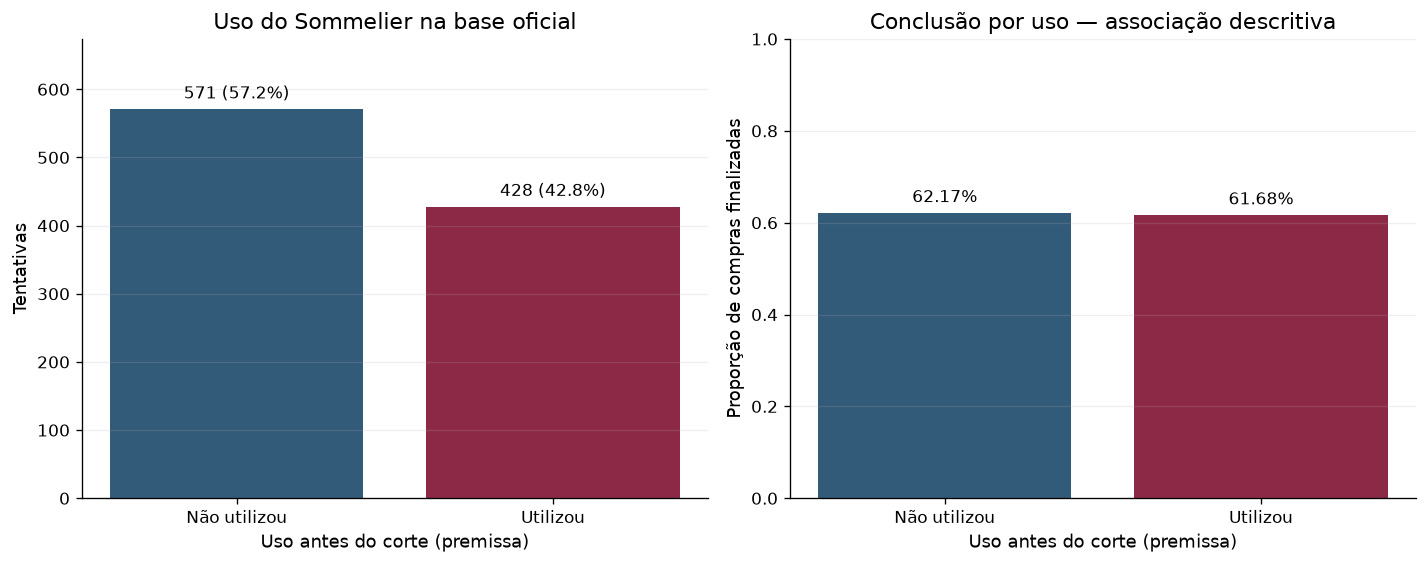

In [5]:
SOMMELIER = 'used_virtual_sommelier'
assert df[SOMMELIER].dtype == bool
assert set(df[SOMMELIER].unique()) == {False, True}
print('Tipo:', df[SOMMELIER].dtype, '| Valores:', sorted(df[SOMMELIER].unique()))
print('Ausentes:', int(df[SOMMELIER].isna().sum()))
tabela_sommelier = df.groupby(SOMMELIER)[ALVO].agg(
    Tentativas='count', Finalizadas='sum', Taxa_de_conclusao='mean',
).reindex([False, True])
tabela_sommelier['Não finalizadas'] = tabela_sommelier['Tentativas'] - tabela_sommelier['Finalizadas']
tabela_sommelier['% das tentativas'] = tabela_sommelier['Tentativas'] / len(df) * 100
display(tabela_sommelier)
display(pd.crosstab(df[SOMMELIER], df[ALVO]).rename(columns={0: 'Não finalizada (0)', 1: 'Finalizada (1)'}))
taxa_sommelier_sem = float(tabela_sommelier.loc[False, 'Taxa_de_conclusao'])
taxa_sommelier_com = float(tabela_sommelier.loc[True, 'Taxa_de_conclusao'])
diferenca_taxa_sommelier = taxa_sommelier_com - taxa_sommelier_sem
display(Markdown(
    f'Conclusão: **{taxa_sommelier_com:.2%} com uso**, contra '
    f'**{taxa_sommelier_sem:.2%} sem uso**. Diferença (com − sem): '
    f'**{diferenca_taxa_sommelier * 100:+.2f} p.p.**. '
    'As taxas são próximas e não indicam associação positiva evidente; '
    'não demonstram influência ou efeito causal.'
))
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8))
rotulos_uso = ['Não utilizou', 'Utilizou']
barras = eixos[0].bar(rotulos_uso, tabela_sommelier['Tentativas'], color=CORES)
eixos[0].bar_label(barras, labels=[f'{n} ({n / len(df):.1%})' for n in tabela_sommelier['Tentativas']], padding=4)
eixos[0].set(title='Uso do Sommelier na base oficial', xlabel='Uso antes do corte (premissa)',
             ylabel='Tentativas', ylim=(0, tabela_sommelier['Tentativas'].max() * 1.18))
barras = eixos[1].bar(rotulos_uso, tabela_sommelier['Taxa_de_conclusao'], color=CORES)
eixos[1].bar_label(barras, labels=[f'{v:.2%}' for v in tabela_sommelier['Taxa_de_conclusao']], padding=4)
eixos[1].set(title='Conclusão por uso — associação descritiva', xlabel='Uso antes do corte (premissa)',
             ylabel='Proporção de compras finalizadas', ylim=(0, 1))
for ax in eixos:
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

### 6. Baseline: previsão da classe majoritária

Antes de treinar a árvore, estabelecemos uma referência simples:
`DummyClassifier(strategy="most_frequent")`. Ele sempre prevê a classe mais
frequente **aprendida no treino**, independentemente dos atributos.

Na base completa, prever sempre compra finalizada resulta em aproximadamente
62% de acurácia. Isso não significa que o modelo saiba identificar abandono:
o recall da classe 0 seria zero. A acurácia do Dummy no teste dependerá da
composição desse conjunto, podendo diferir dos 61,96% globais.

Aqui apenas instanciamos o baseline. Seu ajuste ocorrerá após a separação por
clientes, antes de qualquer árvore. Não é apropriado treiná-lo na base completa.

In [6]:
baseline = DummyClassifier(strategy='most_frequent')
classe_majoritaria_global = int(contagens.idxmax())
acuracia_referencia_global = float(contagens.max() / len(df))
print('Classe majoritária na base completa:', classe_majoritaria_global)
print(f'Acurácia descritiva de sempre prever essa classe: {acuracia_referencia_global:.2%}')
print('Baseline criado; ainda não ajustado. O ajuste utilizará somente o treino.')

Classe majoritária na base completa: 1
Acurácia descritiva de sempre prever essa classe: 61.96%
Baseline criado; ainda não ajustado. O ajuste utilizará somente o treino.


### 7. Seleção das features e hipóteses de negócio

Usaremos **exatamente oito atributos**, definidos antes dos resultados do teste.
As hipóteses justificam investigar as variáveis, mas não afirmam relações causais
nem garantem poder preditivo.

| Feature | Hipótese de negócio a testar |
|---|---|
| `costumer_profile` | Perfis de interesse podem apresentar comportamentos de conclusão diferentes. |
| `costumer_country` | Mercados podem diferir em contexto comercial e condições de atendimento. |
| `costumer_age` | Faixas etárias podem apresentar padrões distintos de consumo. |
| `is_costumer_afiliated` | O vínculo com a vinheria pode estar associado à conclusão da tentativa. |
| `used_virtual_sommelier` | O uso prévio do Sommelier pode conter informação sobre interesse ou apoio à escolha; sua contribuição será medida, sem pressupor benefício. |
| `product_category` | Tipos de vinho podem ter padrões de procura e conclusão diferentes. |
| `price` | O preço anunciado pode se relacionar à decisão de compra. |
| `discount_percentage` | O desconto oferecido pode estar associado à conclusão. |

| Coluna excluída de X | Justificativa |
|---|---|
| `costumer_id` | Identificador sem escala quantitativa; usado exclusivamente para separar grupos. |
| `product_id` | Código nominal; evitar memorização do catálogo no primeiro experimento. |
| `product_label` | Nome redundante com a identificação do produto. |
| `final_price` | Derivado exatamente de preço e desconto; evitar redundância inicial. |
| `date` | Data bruta não modela sazonalidade diretamente; preservada para auditoria e estudo temporal futuro. |
| `costumer_days_since_last_sale` | Origem temporal não documentada; poderia incluir informações posteriores ao evento. |
| `product_review_score` | Não sabemos se a nota já existia antes da tentativa. |
| `did_costumer_finish_sale` | É o alvo y; sua inclusão em X revelaria diretamente a resposta. |

A informação do país inclui categorias com poucos registros; por exemplo,
`argentina` possui apenas 13 linhas. Regras nesses segmentos exigem cautela.
O preço também identifica produtos nesta amostra, o que limita extrapolação para
um catálogo novo. O requisito de pelo menos oito colunas é atendido pela base
de 16 colunas; a escolha de oito entradas decorre das hipóteses, não desse mínimo.

O indicador de Sommelier é incluído como variável experimental de interesse do
projeto, **não porque uma melhora tenha sido observada no teste**. A regra operacional
é usar somente interações ocorridas antes do instante da previsão. Como não há
timestamps de interação, essa disponibilidade é uma premissa não verificável no CSV.
Se o campo representar uso após o desfecho ou um histórico atualizado posteriormente,
deve ser excluído em uma aplicação real. Uma análise de ablação no treino/validação
avaliará sua contribuição sem usar o teste para escolher features.

As exclusões anteriores continuam justificadas: não surgiu documentação temporal
para recência ou nota e a identidade de produto e a fórmula do preço final continuam
redundantes. A presença de uma coluna nova não resolve essas limitações.


In [7]:
FEATURES = [
    'costumer_profile', 'costumer_country', 'costumer_age',
    'is_costumer_afiliated', 'used_virtual_sommelier', 'product_category', 'price', 'discount_percentage',
]
EXCLUIDAS = [c for c in df.columns if c not in FEATURES and c != ALVO]
X = df.loc[:, FEATURES].copy()
y = df[ALVO].astype('int64').copy()
grupos = df['costumer_id'].copy()

assert len(FEATURES) == 8
assert 'costumer_id' not in X.columns and ALVO not in X.columns
print('Features utilizadas:', FEATURES)
print('Excluídas das entradas:', EXCLUIDAS)
print('Alvo:', ALVO)
display(X.head())

Features utilizadas: ['costumer_profile', 'costumer_country', 'costumer_age', 'is_costumer_afiliated', 'used_virtual_sommelier', 'product_category', 'price', 'discount_percentage']
Excluídas das entradas: ['costumer_id', 'costumer_days_since_last_sale', 'product_id', 'product_label', 'final_price', 'product_review_score', 'date']
Alvo: did_costumer_finish_sale


,costumer_profile,costumer_country,costumer_age,is_costumer_afiliated,used_virtual_sommelier,product_category,price,discount_percentage
0,sommelier,brazil,30,False,False,branco,700,38
1,sommelier,brazil,43,False,True,branco,600,0
2,curious_costumer,brazil,49,False,True,rose,650,38
3,invested_costumer,brazil,37,False,False,tinto,800,0
4,invested_costumer,brazil,22,False,True,tinto,1500,0


### 8. Variáveis nominais, binária e numéricas

- **Nominais:** `costumer_profile`, `costumer_country`, `product_category`.
  Usaremos OneHotEncoder, que cria indicadores de presença de cada categoria.
  Não existe hierarquia comprovada entre perfis, países ou categorias de produto.
  Códigos como perfil 1, 2, 3 e 4 imporiam uma ordem artificial aos cortes da árvore.
- **Binárias:** `is_costumer_afiliated` e `used_virtual_sommelier`, convertidas explicitamente de False/True
  para 0/1. Essa transformação tem significado de ausência/presença e não cria
  uma ordem artificial entre múltiplas categorias.
- **Numéricas:** `costumer_age`, `price`, `discount_percentage`. Mantêm sua escala
  original. Árvores utilizam cortes e não precisam de normalização por distância.

A conversão booleana é uma regra fixa, sem parâmetros aprendidos. Por isso,
realizá-la antes da divisão não utiliza informação do teste. Já o encoder será
ajustado exclusivamente dentro da Pipeline e dos folds de treino.

In [8]:
CATEGORICAS = ['costumer_profile', 'costumer_country', 'product_category']
NUMERICAS = ['costumer_age', 'price', 'discount_percentage']
BINARIAS = ['is_costumer_afiliated', 'used_virtual_sommelier']

for coluna in BINARIAS:
    assert set(X[coluna].unique()) <= {False, True}
    X[coluna] = X[coluna].map({False: 0, True: 1}).astype('int8')
display(pd.DataFrame({
    'Variável': CATEGORICAS + NUMERICAS + BINARIAS,
    'Tratamento': ['OneHotEncoder'] * len(CATEGORICAS)
                  + ['Manter escala'] * len(NUMERICAS) + ['False=0; True=1'] * len(BINARIAS),
}))
for coluna in CATEGORICAS:
    print(coluna, '→', sorted(X[coluna].unique()))
for coluna in BINARIAS:
    print(coluna, '→', sorted(X[coluna].unique()))

,Variável,Tratamento
0,costumer_profile,OneHotEncoder
1,costumer_country,OneHotEncoder
2,product_category,OneHotEncoder
3,costumer_age,Manter escala
4,price,Manter escala
5,discount_percentage,Manter escala
6,is_costumer_afiliated,False=0; True=1
7,used_virtual_sommelier,False=0; True=1


costumer_profile → ['curious_costumer', 'invested_costumer', 'new_costumer', 'sommelier']
costumer_country → ['argentina', 'brazil', 'palestine', 'paraguay', 'united_states']
product_category → ['branco', 'rose', 'tinto']
is_costumer_afiliated → [np.int8(0), np.int8(1)]
used_virtual_sommelier → [np.int8(0), np.int8(1)]


### 9. Pipeline de pré-processamento

O ColumnTransformer aplica `OneHotEncoder(handle_unknown="ignore")` às nominais e
mantém as medidas e as duas variáveis binárias. O encoder não remove uma categoria de
referência: árvores não exigem essa remoção. Categorias desconhecidas em novas
tentativas recebem zeros no respectivo bloco, sem interromper a execução.

A Pipeline reúne o pré-processamento e o classificador. Durante a validação cruzada,
cada cópia da Pipeline aprende as categorias somente no treino daquele fold.
Preparar o encoder na base inteira antes da validação contaminaria o processo.
Não há imputação porque não existem ausências; uma futura fonte com nulos exigirá
nova política de tratamento. Nesta etapa construímos apenas a estrutura, sem `fit`.

In [9]:
preprocessamento = ColumnTransformer(
    transformers=[
        ('nominais', OneHotEncoder(handle_unknown='ignore'), CATEGORICAS),
        ('numericas', 'passthrough', NUMERICAS),
        ('binarias', 'passthrough', BINARIAS),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

def criar_pipeline(**parametros):
    return Pipeline([
        ('preprocessamento', clone(preprocessamento)),
        ('classificador', DecisionTreeClassifier(random_state=SEED, **parametros)),
    ])

print(preprocessamento)
print('Pré-processamento construído, sem ajuste na base completa.')

ColumnTransformer(transformers=[('nominais',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['costumer_profile', 'costumer_country',
                                  'product_category']),
                                ('numericas', 'passthrough',
                                 ['costumer_age', 'price',
                                  'discount_percentage']),
                                ('binarias', 'passthrough',
                                 ['is_costumer_afiliated',
                                  'used_virtual_sommelier'])])
Pré-processamento construído, sem ajuste na base completa.


### 10. Separação entre treino e teste por grupos

O **treino** serve para aprender as regras e escolher hiperparâmetros por validação
interna. O **teste** é reservado para a avaliação final do procedimento escolhido.
Avaliar somente os dados usados no ajuste favorece resultados otimistas, pois a
árvore pode memorizar particularidades da amostra.

Usamos `GroupShuffleSplit(test_size=0.20, random_state=42)`. Aqui 20% refere-se
aos **grupos de clientes**, não exatamente às linhas. Como os grupos têm tamanhos
diferentes, mostramos as proporções reais. Esse método não estratifica as classes;
conferimos a composição obtida, sem sortear novamente à procura de um teste favorável.

Nenhum ID pode aparecer nos dois conjuntos. Isso reduz dependência entre tentativas
do mesmo identificador, embora as inconsistências cadastrais impeçam afirmar que
cada ID seja um cliente real. A semente torna o sorteio reprodutível no ambiente
registrado. A avaliação mede generalização a IDs não vistos, dentro da simulação;
não substitui uma validação cronológica para prever compras futuras.

O baseline é ajustado agora, apenas no treino. Para o ajuste da árvore, preparamos
cinco folds de `StratifiedGroupKFold` **dentro do treino**, com tentativa de preservar
as classes e sem interseção de grupos entre treino e validação de cada fold.

#### Distribuições e origem da diferença do baseline

A tabela apresenta quantidade e porcentagem **de cada classe dentro de cada
conjunto**, incluindo a base completa. A coluna de porcentagem das linhas tem outro
denominador: o total de 999 registros. A divisão por grupos mantém 144 IDs no treino
e 36 no teste; o código verifica ausência de interseção tanto no holdout quanto
nos folds internos e confirma que nenhum fold contém linhas do teste final.

O Dummy aprende no treino que a classe majoritária é 1 e prevê 1 para todas as
linhas do teste. Assim, sua acurácia no teste é a **proporção de classe 1 no teste**,
não a proporção global. O GroupShuffleSplit sorteia grupos inteiros, sem estratificar
o alvo; grupos de tamanhos e composições diferentes podem produzir distribuições
distintas. Aqui a taxa global de conclusão é 61,96%, mas a do teste é 55,71%.
Isso explica a diferença do baseline, sem erro de cálculo ou alteração do modelo.
Não se deve trocar a partição ou a semente após observar as métricas para melhorar
o resultado. A composição do teste é uma limitação da estimativa, não um ajuste a fazer.

`StratifiedGroupKFold` está disponível e é adequado à avaliação por IDs não vistos:
existem grupos suficientes e ambas as classes estão presentes em todos os folds.
Ele tenta preservar as proporções sem quebrar grupos; estratificação exata não é
garantida. A validação usa somente o treino/desenvolvimento e **não substitui o
teste final**, que continua separado e não orienta a escolha de parâmetros.


In [10]:
separador = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_treino, idx_teste = next(separador.split(X, y, groups=grupos))
X_treino, X_teste = X.iloc[idx_treino].copy(), X.iloc[idx_teste].copy()
y_treino, y_teste = y.iloc[idx_treino].copy(), y.iloc[idx_teste].copy()
g_treino, g_teste = grupos.iloc[idx_treino].copy(), grupos.iloc[idx_teste].copy()
ids_compartilhados = set(g_treino).intersection(g_teste)
assert not ids_compartilhados, 'Vazamento: mesmo costumer_id em treino e teste.'
assert set(y_treino.unique()) == set(y_teste.unique()) == {0, 1}
assert set(idx_treino).isdisjoint(idx_teste)
assert len(idx_treino) + len(idx_teste) == len(df)

def resumir_particao(nome, rotulos, ids):
    return {
        'Conjunto': nome, 'Linhas': len(rotulos), '% das linhas': len(rotulos) / len(df) * 100,
        'costumer_id únicos': ids.nunique(),
        'Classe 0 — quantidade': int(rotulos.eq(0).sum()),
        'Classe 0 — %': rotulos.eq(0).mean() * 100,
        'Classe 1 — quantidade': int(rotulos.eq(1).sum()),
        'Classe 1 — %': rotulos.eq(1).mean() * 100,
    }

particoes = pd.DataFrame([
    resumir_particao('Dataset completo', y, grupos),
    resumir_particao('Treino', y_treino, g_treino),
    resumir_particao('Teste reservado', y_teste, g_teste),
]).set_index('Conjunto')
display(particoes)
print('IDs compartilhados entre treino e teste:', len(ids_compartilhados))
baseline.fit(X_treino, y_treino)
print('Classe que o Dummy prevê, aprendida no treino:', int(baseline.predict(X_treino.iloc[:1])[0]))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_treino, y_treino, groups=g_treino))
resumo_folds = []
for numero, (it, iv) in enumerate(FOLDS, start=1):
    ids_fit, ids_val = set(g_treino.iloc[it]), set(g_treino.iloc[iv])
    assert ids_fit.isdisjoint(ids_val)
    assert ids_fit.isdisjoint(set(g_teste)) and ids_val.isdisjoint(set(g_teste))
    assert set(X_treino.index[it]).isdisjoint(X_teste.index)
    assert set(X_treino.index[iv]).isdisjoint(X_teste.index)
    assert set(y_treino.iloc[it].unique()) == set(y_treino.iloc[iv].unique()) == {0, 1}
    resumo_folds.append({
        'Fold': numero, 'Linhas de ajuste': len(it), 'Linhas de validação': len(iv),
        'IDs compartilhados': len(ids_fit & ids_val),
        'Classe 0 na validação': int(y_treino.iloc[iv].eq(0).sum()),
        'Classe 1 na validação': int(y_treino.iloc[iv].eq(1).sum()),
        '% classe 1 na validação': y_treino.iloc[iv].mean() * 100,
    })
assert np.array_equal(
    np.sort(np.concatenate([iv for _, iv in FOLDS])),
    np.arange(len(X_treino)),
), 'Cada registro de desenvolvimento deve ser validado exatamente uma vez.'
display(pd.DataFrame(resumo_folds).set_index('Fold'))
print('Auditoria aprovada: zero IDs compartilhados; teste ausente de todos os folds.')

display(Markdown(
    f'A proporção de conclusão é {y_treino.mean():.2%} no treino e '
    f'{y_teste.mean():.2%} no teste. O sorteio por grupos não estratifica o alvo, '
    'e grupos de tamanhos diferentes produzem proporções distintas. '
    'Essa diferença deve ser considerada ao interpretar a queda no teste. '
    'O sorteio foi mantido, sem procurar outra partição após observar seu resultado.'
))

,Linhas,% das linhas,costumer_id únicos,Classe 0 — quantidade,Classe 0 — %,Classe 1 — quantidade,Classe 1 — %
Conjunto,,,,,,,
Dataset completo,999,100.0000,180,380,38.0380,619,61.9620
Treino,780,78.0781,144,283,36.2821,497,63.7179
Teste reservado,219,21.9219,36,97,44.2922,122,55.7078


IDs compartilhados entre treino e teste: 0
Classe que o Dummy prevê, aprendida no treino: 1


,Linhas de ajuste,Linhas de validação,IDs compartilhados,Classe 0 na validação,Classe 1 na validação,% classe 1 na validação
Fold,,,,,,
1,624,156,0,57,99,63.4615
2,621,159,0,57,102,64.1509
3,628,152,0,56,96,63.1579
4,621,159,0,57,102,64.1509
5,626,154,0,56,98,63.6364


Auditoria aprovada: zero IDs compartilhados; teste ausente de todos os folds.


A proporção de conclusão é 63.72% no treino e 55.71% no teste. O sorteio por grupos não estratifica o alvo, e grupos de tamanhos diferentes produzem proporções distintas. Essa diferença deve ser considerada ao interpretar a queda no teste. O sorteio foi mantido, sem procurar outra partição após observar seu resultado.

### 11. Por que uma Árvore de Decisão?

Uma árvore particiona as entradas por perguntas como “o preço é menor ou igual
a determinado valor?”. Folhas atribuem uma classe e estimam probabilidades a partir
da distribuição das classes nos registros de treino que chegam a cada folha.

Ela é adequada didaticamente a esta classificação binária porque permite visualizar
regras, modelar relações não lineares e interações entre atributos, trabalhar com
uma base pequena e examinar importâncias preditivas. A impureza de Gini mede a mistura
das classes em um nó: em classificação binária, 0 indica um nó puro e 0,5 indica
mistura equilibrada. Os cortes buscam reduzir essa impureza no treino.

Suas limitações incluem sobreajuste, instabilidade diante de mudanças na amostra e
sensibilidade à profundidade e ao tamanho das folhas. Importância de uma variável
não significa causalidade, pode favorecer variáveis com muitos cortes possíveis
e pode ser dividida entre atributos dependentes. A base é apropriada para testar
o método, mas não garante que suas features tenham sinal preditivo suficiente.

In [11]:
modelo_inicial = criar_pipeline(max_depth=3, min_samples_split=2, min_samples_leaf=20)
print('Modelo inicial:', modelo_inicial.named_steps['classificador'])
print('Critério de impureza:', modelo_inicial.named_steps['classificador'].criterion)

Modelo inicial: DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=42)
Critério de impureza: gini


### 12. Treinamento do modelo inicial

Começamos com `max_depth=3`, `min_samples_split=2`, `min_samples_leaf=20` e
`random_state=42`. A profundidade limita o número de decisões sucessivas, enquanto
o mínimo de registros por folha evita regras apoiadas em pouquíssimos exemplos.
Esses valores são um ponto de partida, não uma afirmação de optimalidade.

Executamos validação cruzada nos cinco folds internos para comparar desempenho
de ajuste e validação. O baseline utiliza exatamente os mesmos folds. O teste
permanece fora desta etapa. Não aplicamos reamostragem. A árvore inicial não usa pesos; a grade da
seção seguinte também avaliará pesos balanceados, pois o desbalanceamento é moderado e será acompanhado por métricas
por classe e pela seleção com F1 macro.

In [12]:
SCORING = {
    'accuracy': 'accuracy', 'f1_macro': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy',
}
cv_inicial = cross_validate(
    clone(modelo_inicial), X_treino, y_treino, cv=FOLDS,
    scoring=SCORING, return_train_score=True, n_jobs=1,
)
cv_baseline = cross_validate(
    clone(baseline), X_treino, y_treino, cv=FOLDS,
    scoring=SCORING, return_train_score=True, n_jobs=1,
)
modelo_inicial.fit(X_treino, y_treino)
resumo_inicial = []
for nome, resultado in [('Dummy', cv_baseline), ('Árvore inicial', cv_inicial)]:
    for metrica in SCORING:
        resumo_inicial.append({
            'Modelo': nome, 'Métrica': metrica,
            'Ajuste nos folds (média)': resultado[f'train_{metrica}'].mean(),
            'Validação (média)': resultado[f'test_{metrica}'].mean(),
            'Validação (desvio padrão)': resultado[f'test_{metrica}'].std(ddof=0),
        })
display(pd.DataFrame(resumo_inicial).set_index(['Modelo', 'Métrica']))

Ajuste nos folds (média)  Validação (média)  \
Modelo         Métrica                                                          
Dummy          accuracy                             0.6372             0.6371   
               f1_macro                             0.3892             0.3892   
               balanced_accuracy                    0.5000             0.5000   
Árvore inicial accuracy                             0.6468             0.6203   
               f1_macro                             0.4811             0.4274   
               balanced_accuracy                    0.5323             0.4989   

                                  Validação (desvio padrão)  
Modelo         Métrica                                       
Dummy          accuracy                              0.0039  
               f1_macro                              0.0015  
               balanced_accuracy                     0.0000  
Árvore inicial accuracy                              0.0178  
               f1_macro                              0.0335  
               balanced_accuracy                     0.0203

### 13. Ajuste da complexidade somente no treino

O GridSearchCV testa combinações de profundidade máxima, mínimo para dividir um nó
e mínimo de registros por folha. Revisamos a grade para manter interpretabilidade: profundidade de 1 a 5,
folhas com no mínimo 10, 20 ou 40 registros e mínimo de divisão de 2, 20 ou 40.
Também comparamos `class_weight=None` e `"balanced"`; o segundo atribui pesos
inversamente proporcionais às frequências de classes em cada ajuste de treino.
Essas restrições são definidas antes da avaliação final, sem reaproveitar os
melhores parâmetros anteriores. Os pesos, quando usados, não são aprendidos no teste. A Pipeline inteira é reajustada em cada fold: categorias da validação não
são aprendidas antecipadamente pelo encoder.

**Critério de escolha definido antes do teste:** maior F1 macro médio na validação
por grupos. Essa métrica atribui igual peso ao F1 de cada classe, ao contrário de
uma média ponderada pelo tamanho das classes. Acurácia e balanced accuracy são
acompanhadas como métricas secundárias. O procedimento não otimiza diretamente custos
comerciais, que não estão documentados na base.

O melhor resultado de validação foi escolhido entre várias configurações e pode
ser otimista por seleção. O teste reservado oferece a avaliação final independente
desse ajuste. A diferença treino–validação é um diagnóstico, sem constituir sozinha
um teste estatístico de sobreajuste.

In [13]:
grade = {
    'classificador__max_depth': [1, 2, 3, 4, 5],
    'classificador__min_samples_split': [2, 20, 40],
    'classificador__min_samples_leaf': [10, 20, 40],
    'classificador__class_weight': [None, 'balanced'],
}
busca = GridSearchCV(
    estimator=criar_pipeline(), param_grid=grade, scoring=SCORING,
    refit='f1_macro', cv=FOLDS, return_train_score=True,
    n_jobs=1, error_score='raise',
)
busca.fit(X_treino, y_treino)
modelo_final = busca.best_estimator_
indice_melhor = busca.best_index_
resultados_cv = pd.DataFrame(busca.cv_results_)
colunas_cv = [
    'rank_test_f1_macro', 'param_classificador__max_depth',
    'param_classificador__min_samples_split', 'param_classificador__min_samples_leaf',
    'param_classificador__class_weight',
    'mean_train_f1_macro', 'mean_test_f1_macro', 'std_test_f1_macro',
    'mean_test_accuracy', 'mean_test_balanced_accuracy',
]
tabela_cv = resultados_cv[colunas_cv].sort_values(
    ['rank_test_f1_macro', 'std_test_f1_macro'], kind='stable',
).copy()
tabela_cv['Diferença ajuste − validação (F1 macro)'] = (
    tabela_cv['mean_train_f1_macro'] - tabela_cv['mean_test_f1_macro']
)
print(f'{len(resultados_cv)} configurações × {len(FOLDS)} folds = '
      f'{len(resultados_cv) * len(FOLDS)} ajustes de validação, além do refit final.')
print('Parâmetros selecionados:', busca.best_params_)
print(f'Melhor F1 macro médio de validação: {busca.best_score_:.4f}')
display(tabela_cv.head(15).rename(columns={
    'rank_test_f1_macro': 'Posição por F1 macro',
    'param_classificador__max_depth': 'max_depth',
    'param_classificador__min_samples_split': 'min_samples_split',
    'param_classificador__min_samples_leaf': 'min_samples_leaf',
    'param_classificador__class_weight': 'class_weight',
}))
print('Configuração com maior diferença ajuste–validação:')
display(tabela_cv.nlargest(1, 'Diferença ajuste − validação (F1 macro)'))

90 configurações × 5 folds = 450 ajustes de validação, além do refit final.
Parâmetros selecionados: {'classificador__class_weight': 'balanced', 'classificador__max_depth': 1, 'classificador__min_samples_leaf': 10, 'classificador__min_samples_split': 2}
Melhor F1 macro médio de validação: 0.4964


,Posição por F1 macro,max_depth,min_samples_split,min_samples_leaf,class_weight,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,mean_test_balanced_accuracy,Diferença ajuste − validação (F1 macro)
45,1,1,2,10,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
46,1,1,20,10,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
47,1,1,40,10,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
48,1,1,2,20,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
49,1,1,20,20,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
50,1,1,40,20,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
51,1,1,2,40,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
52,1,1,20,40,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
53,1,1,40,40,balanced,0.5049,0.4964,0.0191,0.4977,0.5481,0.0085
87,10,5,2,40,balanced,0.5732,0.4922,0.0534,0.5017,0.5089,0.0810


Configuração com maior diferença ajuste–validação:


,rank_test_f1_macro,param_classificador__max_depth,param_classificador__min_samples_split,param_classificador__min_samples_leaf,param_classificador__class_weight,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,mean_test_balanced_accuracy,Diferença ajuste − validação (F1 macro)
83,47,5,40,10,balanced,0.6012,0.4709,0.0539,0.4901,0.4947,0.1303


### 13.1. Contribuição do Sommelier: ablação no treino/validação

Para investigar se o indicador acrescenta informação, retiramos somente
`used_virtual_sommelier` e repetimos os mesmos folds internos com os hiperparâmetros
selecionados para a árvore de oito entradas. Nenhuma predição de teste é usada.

Esta é uma **ablação controlada com hiperparâmetros fixos**, não uma comparação entre
duas buscas independentes. O modelo completo já foi selecionado nesses folds, de
modo que a comparação pode favorecê-lo por seleção. Uma diferença pequena não
comprova melhora robusta. A lista final de oito entradas foi definida pela hipótese
do projeto e não será escolhida olhando o teste. Os resultados avaliam contribuição
preditiva, sem estabelecer que o uso do Sommelier cause compras.

In [14]:
binarias_sem_sommelier = ['is_costumer_afiliated']
prep_sem_sommelier = ColumnTransformer([
    ('nominais', OneHotEncoder(handle_unknown='ignore'), CATEGORICAS),
    ('numericas', 'passthrough', NUMERICAS),
    ('binarias', 'passthrough', binarias_sem_sommelier),
], remainder='drop', verbose_feature_names_out=True)
features_sem_sommelier = [c for c in FEATURES if c != SOMMELIER]
modelo_sem_sommelier = clone(modelo_final).set_params(preprocessamento=prep_sem_sommelier)
cv_sem_sommelier = cross_validate(
    modelo_sem_sommelier, X_treino[features_sem_sommelier], y_treino,
    cv=FOLDS, scoring=SCORING, return_train_score=False, n_jobs=1,
)
ablation = pd.DataFrame(index=list(SCORING))
ablation['Com Sommelier — média CV'] = [
    float(resultados_cv.iloc[indice_melhor][f'mean_test_{m}']) for m in SCORING
]
ablation['Sem Sommelier — média CV'] = [cv_sem_sommelier[f'test_{m}'].mean() for m in SCORING]
ablation['Com − sem (p.p.)'] = (
    ablation['Com Sommelier — média CV'] - ablation['Sem Sommelier — média CV']
) * 100
display(ablation.rename_axis('Métrica'))
impacto_sommelier_cv = float(ablation.loc['f1_macro', 'Com − sem (p.p.)'] / 100)
display(Markdown(
    f'Com os mesmos hiperparâmetros, incluir o indicador variou o F1 macro médio '
    f'em **{impacto_sommelier_cv * 100:+.2f} p.p.**. '
    'A diferença é descritiva, sujeita à variabilidade entre grupos e ao viés de seleção; '
    'não comprova influência positiva ou negativa da funcionalidade sobre vendas.'
))

,Com Sommelier — média CV,Sem Sommelier — média CV,Com − sem (p.p.)
Métrica,,,
accuracy,0.4977,0.4977,0.0
f1_macro,0.4964,0.4964,0.0
balanced_accuracy,0.5481,0.5481,0.0


Com os mesmos hiperparâmetros, incluir o indicador variou o F1 macro médio em **+0.00 p.p.**. A diferença é descritiva, sujeita à variabilidade entre grupos e ao viés de seleção; não comprova influência positiva ou negativa da funcionalidade sobre vendas.

### 13.2. Estabilidade na validação cruzada por clientes

Reunimos os resultados dos **mesmos cinco folds internos**, sem novos sorteios,
sem acessar o teste e sem ampliar a busca de parâmetros. A árvore apresentada é a
configuração selecionada pelo F1 macro da seção 13. O Dummy é reajustado nos mesmos
subconjuntos de treino de cada fold; nunca aprende a frequência do fold de validação.

As tabelas mostram resultados por fold, média e desvio padrão de accuracy, F1 macro
e balanced accuracy. As médias atribuem peso igual aos cinco folds, cujos tamanhos
são próximos, mas não idênticos. Desvio padrão é a dispersão descritiva das cinco
pontuações (`ddof=0`); não é intervalo de confiança nem teste de significância.
Treinos de folds distintos se sobrepõem, portanto suas pontuações não são amostras
independentes para uma análise inferencial simples.

**Limite da interpretação:** os folds também foram usados para selecionar os
hiperparâmetros da árvore. Seu melhor resultado tem possível otimismo de seleção;
essa tabela descreve a estabilidade interna, não uma avaliação externa independente
do processo completo de seleção. Não realizamos validação aninhada. O holdout
separado por clientes permanece a avaliação final e não é substituído pela média CV.
O resultado desta revisão não será usado para trocar features, parâmetros ou limiar.

In [15]:
# Reutilizar as pontuações já calculadas, sem refazer ou expandir a seleção.
pontuacoes_cv = []
for i, (_, validacao) in enumerate(FOLDS):
    pontuacoes_cv.append({
        'Modelo': 'DummyClassifier', 'Fold': i + 1,
        'Registros de validação': len(validacao),
        'Accuracy': float(cv_baseline['test_accuracy'][i]),
        'F1 macro': float(cv_baseline['test_f1_macro'][i]),
        'Balanced Accuracy': float(cv_baseline['test_balanced_accuracy'][i]),
    })
    pontuacoes_cv.append({
        'Modelo': 'Árvore selecionada', 'Fold': i + 1,
        'Registros de validação': len(validacao),
        'Accuracy': float(resultados_cv.iloc[indice_melhor][f'split{i}_test_accuracy']),
        'F1 macro': float(resultados_cv.iloc[indice_melhor][f'split{i}_test_f1_macro']),
        'Balanced Accuracy': float(resultados_cv.iloc[indice_melhor][f'split{i}_test_balanced_accuracy']),
    })
desempenho_folds = pd.DataFrame(pontuacoes_cv)
display(desempenho_folds.set_index(['Modelo', 'Fold']).sort_index())

linhas_estabilidade = []
for nome, resultados in desempenho_folds.groupby('Modelo', sort=False):
    linha = {'Modelo': nome, 'Folds': len(resultados)}
    for metrica in ['Accuracy', 'F1 macro', 'Balanced Accuracy']:
        valores = resultados[metrica].to_numpy()
        linha[f'{metrica} — média'] = float(valores.mean())
        linha[f'{metrica} — DP'] = float(valores.std(ddof=0))
    linhas_estabilidade.append(linha)
estabilidade_cv = pd.DataFrame(linhas_estabilidade).set_index('Modelo')
display(estabilidade_cv)

assert np.isclose(
    estabilidade_cv.loc['Árvore selecionada', 'F1 macro — média'], busca.best_score_,
)
assert np.isclose(
    estabilidade_cv.loc['Árvore selecionada', 'Accuracy — DP'],
    resultados_cv.iloc[indice_melhor]['std_test_accuracy'],
)
display(Markdown(
    'As duas linhas usam exatamente os mesmos grupos de validação. '
    'Balanced accuracy igual a 0,5 no Dummy é esperada quando ele prevê apenas '
    'uma classe e ambas estão presentes. Baixa dispersão indica regularidade '
    'entre esses folds, não boa qualidade preditiva ou garantia de generalização.'
))

Registros de validação  Accuracy  F1 macro  \
Modelo             Fold                                               
DummyClassifier    1                        156    0.6346    0.3882   
                   2                        159    0.6415    0.3908   
                   3                        152    0.6316    0.3871   
                   4                        159    0.6415    0.3908   
                   5                        154    0.6364    0.3889   
Árvore selecionada 1                        156    0.5064    0.5062   
                   2                        159    0.4843    0.4796   
                   3                        152    0.5263    0.5250   
                   4                        159    0.4717    0.4717   
                   5                        154    0.5000    0.4995   

                         Balanced Accuracy  
Modelo             Fold                     
DummyClassifier    1                0.5000  
                   2                0.5000  
                   3                0.5000  
                   4                0.5000  
                   5                0.5000  
Árvore selecionada 1                0.5404  
                   2                0.5555  
                   3                0.5804  
                   4                0.5147  
                   5                0.5497

,Folds,Accuracy — média,Accuracy — DP,F1 macro — média,F1 macro — DP,Balanced Accuracy — média,Balanced Accuracy — DP
Modelo,,,,,,,
DummyClassifier,5,0.6371,0.0039,0.3892,0.0015,0.5000,0.0000
Árvore selecionada,5,0.4977,0.0187,0.4964,0.0191,0.5481,0.0213


As duas linhas usam exatamente os mesmos grupos de validação. Balanced accuracy igual a 0,5 no Dummy é esperada quando ele prevê apenas uma classe e ambas estão presentes. Baixa dispersão indica regularidade entre esses folds, não boa qualidade preditiva ou garantia de generalização.

### 14. Avaliação final no conjunto de teste

Com a configuração escolhida e reajustada no treino completo, utilizamos o teste
reservado. As predições são calculadas uma vez e reutilizadas nas próximas análises;
não alteraremos a configuração, as features ou o limiar após observar o teste.

- **Accuracy:** proporção total de acertos.
- **Precision da classe 1:** entre as previsões de conclusão, quantas concluíram.
- **Recall da classe 1:** entre as compras concluídas, quantas foram identificadas.
- **F1 da classe 1:** média harmônica entre sua precisão e seu recall.
- **Métricas da classe 0:** mesmas definições, tomando a não conclusão como a classe
  de interesse. Seu recall mede quantas não conclusões conseguimos detectar.
- **F1 macro:** média não ponderada dos F1 das duas classes.
- **Balanced Accuracy:** média dos recalls das duas classes.

No classification report, `support` é o número real de exemplos de cada classe.
Usamos `zero_division=0` para representar a ausência de previsões de uma classe
sem gerar uma precisão artificialmente alta ou ocultar o problema.

In [16]:
# A configuração está congelada antes destas predições no teste.
pred_dummy = baseline.predict(X_teste)
pred_arvore = modelo_final.predict(X_teste)
classes_modelo = modelo_final.named_steps['classificador'].classes_.tolist()
indice_classe_1 = classes_modelo.index(1)
prob_arvore_1 = modelo_final.predict_proba(X_teste)[:, indice_classe_1]
indice_dummy_1 = baseline.classes_.tolist().index(1)
prob_dummy_1 = baseline.predict_proba(X_teste)[:, indice_dummy_1]

def calcular_metricas(rotulos, predicoes):
    return {
        'Accuracy': accuracy_score(rotulos, predicoes),
        'Precision (classe 1)': precision_score(rotulos, predicoes, pos_label=1, zero_division=0),
        'Recall (classe 1)': recall_score(rotulos, predicoes, pos_label=1, zero_division=0),
        'F1 (classe 1)': f1_score(rotulos, predicoes, pos_label=1, zero_division=0),
        'Precision (classe 0)': precision_score(rotulos, predicoes, pos_label=0, zero_division=0),
        'Recall (classe 0)': recall_score(rotulos, predicoes, pos_label=0, zero_division=0),
        'F1 (classe 0)': f1_score(rotulos, predicoes, pos_label=0, zero_division=0),
        'F1 macro': f1_score(rotulos, predicoes, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(rotulos, predicoes),
    }

metricas_arvore = calcular_metricas(y_teste, pred_arvore)
metricas_dummy = calcular_metricas(y_teste, pred_dummy)
display(pd.Series(metricas_arvore, name='Árvore — teste').to_frame())
relatorio_arvore = pd.DataFrame(classification_report(
    y_teste, pred_arvore, labels=[0, 1], target_names=NOMES_CLASSES,
    output_dict=True, zero_division=0,
)).T
display(relatorio_arvore)
print(classification_report(
    y_teste, pred_arvore, labels=[0, 1], target_names=NOMES_CLASSES,
    digits=4, zero_division=0,
))

,Árvore — teste
Accuracy,0.4521
Precision (classe 1),0.5147
Recall (classe 1),0.2869
F1 (classe 1),0.3684
Precision (classe 0),0.4238
Recall (classe 0),0.6598
F1 (classe 0),0.5161
F1 macro,0.4423
Balanced Accuracy,0.4733


,precision,recall,f1-score,support
Não finalizada (0),0.4238,0.6598,0.5161,97.0000
Finalizada (1),0.5147,0.2869,0.3684,122.0000
accuracy,0.4521,0.4521,0.4521,0.4521
macro avg,0.4693,0.4733,0.4423,219.0000
weighted avg,0.4745,0.4521,0.4338,219.0000


                    precision    recall  f1-score   support

Não finalizada (0)     0.4238    0.6598    0.5161        97
    Finalizada (1)     0.5147    0.2869    0.3684       122

          accuracy                         0.4521       219
         macro avg     0.4693    0.4733    0.4423       219
      weighted avg     0.4745    0.4521    0.4338       219



### 15. Comparação explícita com o baseline

A tabela compara os dois classificadores no mesmo teste e apresenta a diferença
árvore − Dummy em pontos percentuais. A árvore precisa justificar sua complexidade
com melhor capacidade de discriminar as classes, especialmente as não conclusões.
Superar 60% de acurácia, isoladamente, não atende a esse critério.

As diferenças são descritivas para este teste; não representam prova de melhoria
estatisticamente significativa nem garantia de desempenho em produção. Uma melhora
em F1 macro pode ocorrer junto com perda de acurácia, expondo um compromisso entre
o desempenho das duas classes.

,Accuracy,Precision (classe 1),Recall (classe 1),F1 (classe 1),Precision (classe 0),Recall (classe 0),F1 (classe 0),F1 macro,Balanced Accuracy
DummyClassifier,0.5571,0.5571,1.0000,0.7155,0.0000,0.0000,0.0000,0.3578,0.5000
Árvore de Decisão,0.4521,0.5147,0.2869,0.3684,0.4238,0.6598,0.5161,0.4423,0.4733


,Árvore − Dummy (pontos percentuais)
Accuracy,-10.5023
Precision (classe 1),-4.2372
Recall (classe 1),-71.3115
F1 (classe 1),-34.7121
Precision (classe 0),42.3841
Recall (classe 0),65.9794
F1 (classe 0),51.6129
F1 macro,8.4504
Balanced Accuracy,-2.6660


**Leitura do resultado real:** A árvore não supera simultaneamente o Dummy em F1 macro e balanced accuracy neste teste. Não há melhora consistente nessas duas métricas para justificar seu uso comercial a partir deste experimento. A diferença de acurácia foi -10.50 p.p.; a de F1 macro, +8.45 p.p.; e a de balanced accuracy, -2.67 p.p.

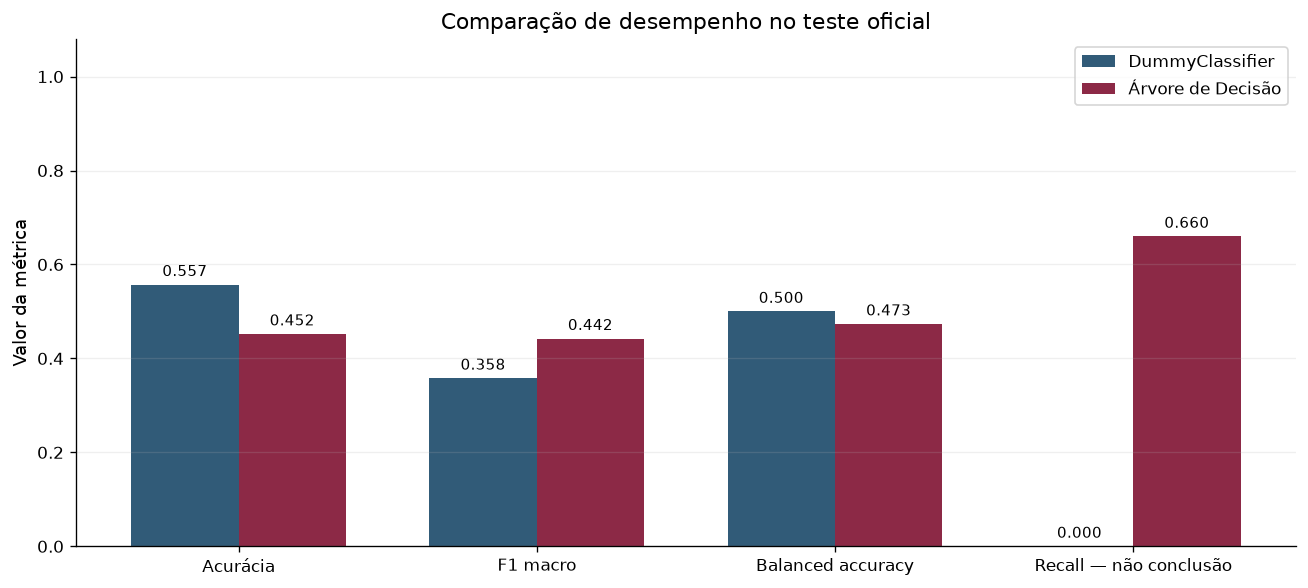

In [17]:
comparacao = pd.DataFrame({
    'DummyClassifier': metricas_dummy, 'Árvore de Decisão': metricas_arvore,
}).T
display(comparacao)
ganhos = comparacao.loc['Árvore de Decisão'] - comparacao.loc['DummyClassifier']
display((ganhos * 100).rename('Árvore − Dummy (pontos percentuais)').to_frame())

if ganhos['F1 macro'] > 0 and ganhos['Balanced Accuracy'] > 0:
    leitura_baseline = (
        'A árvore supera descritivamente o Dummy em F1 macro e balanced accuracy '
        'neste teste. O tamanho dos ganhos e as limitações da simulação ainda '
        'precisam ser considerados antes de afirmar utilidade prática.'
    )
else:
    leitura_baseline = (
        'A árvore não supera simultaneamente o Dummy em F1 macro e balanced accuracy '
        'neste teste. Não há melhora consistente nessas duas métricas para '
        'justificar seu uso comercial a partir deste experimento.'
    )
display(Markdown(
    f'**Leitura do resultado real:** {leitura_baseline} '
    f'A diferença de acurácia foi {ganhos["Accuracy"] * 100:+.2f} p.p.; '
    f'a de F1 macro, {ganhos["F1 macro"] * 100:+.2f} p.p.; '
    f'e a de balanced accuracy, {ganhos["Balanced Accuracy"] * 100:+.2f} p.p.'
))

metricas_grafico = ['Accuracy', 'F1 macro', 'Balanced Accuracy', 'Recall (classe 0)']
fig, ax = plt.subplots(figsize=(11, 5))
posicoes_metricas = np.arange(len(metricas_grafico))
for deslocamento, (nome, linha), cor in zip(
    [-0.18, 0.18], comparacao.iterrows(), CORES,
):
    barras = ax.bar(posicoes_metricas + deslocamento, linha[metricas_grafico],
                    width=0.36, label=nome, color=cor)
    ax.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(posicoes_metricas, ['Acurácia', 'F1 macro', 'Balanced accuracy', 'Recall — não conclusão'])
ax.set(title='Comparação de desempenho no teste oficial', ylabel='Valor da métrica', ylim=(0, 1.08))
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)


### 16. Matriz de confusão no contexto da Vinheria

Adotamos **compra finalizada (1) como classe positiva**. As linhas representam o
resultado real e as colunas, a previsão:

| Caso | Significado para a Vinheria |
|---|---|
| Verdadeiro negativo (TN) | Prevê não finalização e a compra não é finalizada. |
| Falso positivo (FP) | Prevê finalização, mas a compra não é finalizada; perde uma oportunidade de identificar risco. |
| Falso negativo (FN) | Prevê não finalização, mas a compra é finalizada; poderia motivar intervenção desnecessária. |
| Verdadeiro positivo (TP) | Prevê finalização e a compra é finalizada. |

O recall da classe 0 é `TN / (TN + FP)`. Ele é especialmente relevante para
identificar tentativas que não concluem, embora não substitua a análise de custos
de abordagens comerciais. A figura compara contagens dos dois modelos e mostra
também a matriz da árvore normalizada por classe real.

,Caso,Quantidade,Interpretação
0,TN,64,Não conclusão corretamente identificada
1,FP,33,"Previu conclusão, mas não concluiu"
2,FN,87,"Previu não conclusão, mas concluiu"
3,TP,35,Conclusão corretamente identificada


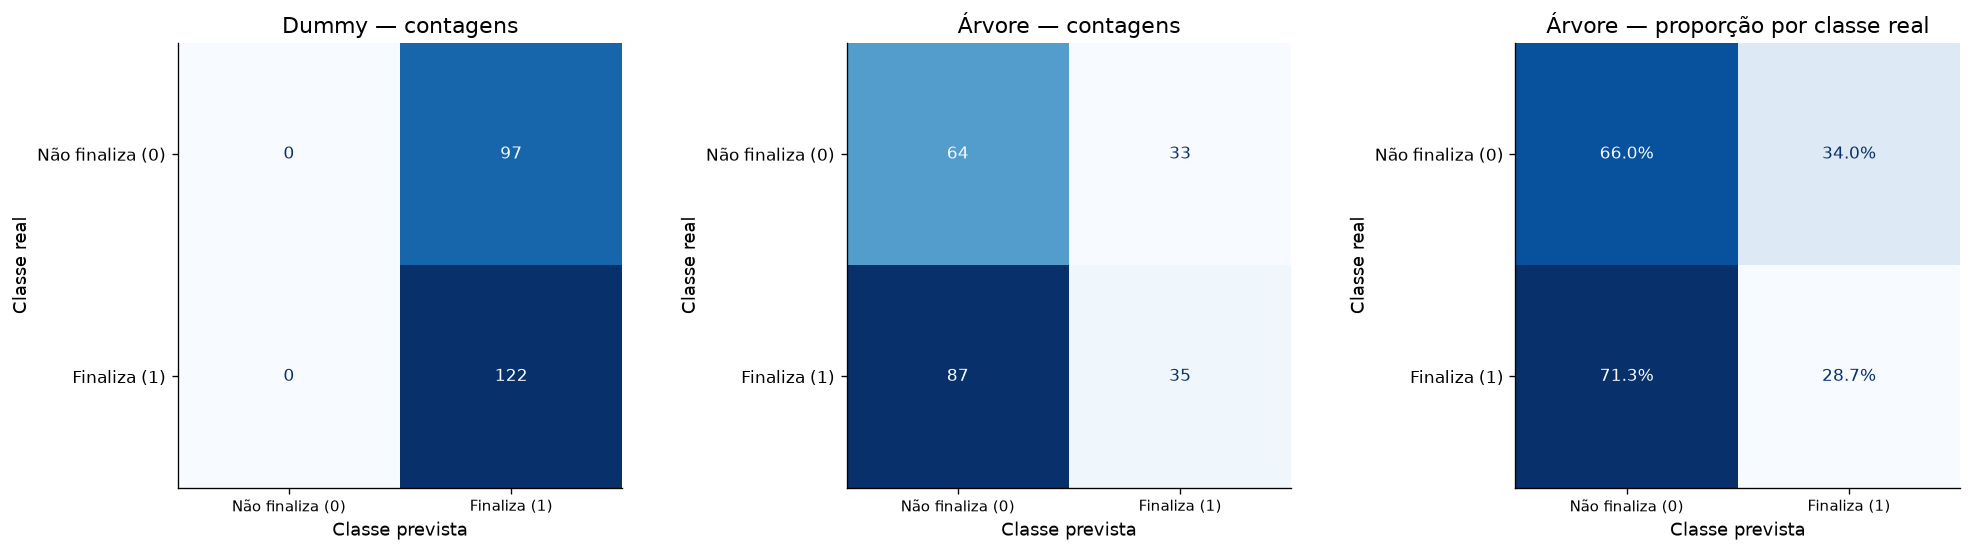

A árvore identificou **64 de 97 não conclusões** (recall 0 = 65.98%) e **35 de 122 conclusões** (recall 1 = 28.69%). Erros: 33 falsos positivos e 87 falsos negativos.

In [18]:
matriz = confusion_matrix(y_teste, pred_arvore, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
display(pd.DataFrame({
    'Caso': ['TN', 'FP', 'FN', 'TP'],
    'Quantidade': [tn, fp, fn, tp],
    'Interpretação': [
        'Não conclusão corretamente identificada',
        'Previu conclusão, mas não concluiu',
        'Previu não conclusão, mas concluiu',
        'Conclusão corretamente identificada',
    ],
}))
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.7))
for ax, pred, titulo, normalizar in [
    (eixos[0], pred_dummy, 'Dummy — contagens', None),
    (eixos[1], pred_arvore, 'Árvore — contagens', None),
    (eixos[2], pred_arvore, 'Árvore — proporção por classe real', 'true'),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_teste, pred, labels=[0, 1], display_labels=['Não finaliza (0)', 'Finaliza (1)'],
        normalize=normalizar, cmap='Blues', colorbar=False, ax=ax,
        values_format='.1%' if normalizar else 'd',
    )
    ax.set(title=titulo, xlabel='Classe prevista', ylabel='Classe real')
    ax.tick_params(axis='x', labelsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
display(Markdown(
    f'A árvore identificou **{tn} de {tn + fp} não conclusões** '
    f'(recall 0 = {tn / (tn + fp):.2%}) e **{tp} de {tp + fn} conclusões** '
    f'(recall 1 = {tp / (tp + fn):.2%}). '
    f'Erros: {fp} falsos positivos e {fn} falsos negativos.'
))

### 17. Importância das features após OneHotEncoder

Recuperamos os nomes transformados pelo pré-processador já ajustado. A importância
da árvore corresponde à redução normalizada de impureza atribuída aos cortes no
treino. Zero indica que a feature não foi usada em cortes; não prova irrelevância
em qualquer contexto ou algoritmo.

Além da tabela completa de indicadores, agregamos as importâncias das categorias
para suas oito variáveis de origem. Isso facilita a explicação ao grupo e evita
confundir uma única categoria com o atributo inteiro. A agregação é uma soma de
importâncias, não uma nova medida causal. As importâncias são calculadas no treino
e não demonstram, sozinhas, contribuição preditiva fora da amostra.

A tabela mostra explicitamente a importância e a posição de `used_virtual_sommelier`.
Empates recebem a mesma posição. Se houver `class_weight="balanced"`, as importâncias
e a impureza refletem o ajuste ponderado, e não uma estimativa de efeito comercial.


,Feature transformada,Variável de origem,Importância
0,numericas__discount_percentage,discount_percentage,1.0
1,nominais__costumer_profile_curious_costumer,costumer_profile,0.0
2,nominais__costumer_profile_invested_costumer,costumer_profile,0.0
3,nominais__costumer_profile_new_costumer,costumer_profile,0.0
4,nominais__costumer_profile_sommelier,costumer_profile,0.0
5,nominais__costumer_country_argentina,costumer_country,0.0
6,nominais__costumer_country_brazil,costumer_country,0.0
7,nominais__costumer_country_palestine,costumer_country,0.0
8,nominais__costumer_country_paraguay,costumer_country,0.0
9,nominais__costumer_country_united_states,costumer_country,0.0


,Posição (empates compartilham posição),Importância agregada
Variável de origem,,
discount_percentage,1,1.0
costumer_profile,2,0.0
costumer_country,2,0.0
costumer_age,2,0.0
is_costumer_afiliated,2,0.0
used_virtual_sommelier,2,0.0
product_category,2,0.0
price,2,0.0


Cinco primeiras posições da tabela (zeros empatados seguem a ordem original):


,Posição (empates compartilham posição),Importância agregada
Variável de origem,,
discount_percentage,1,1.0
costumer_profile,2,0.0
costumer_country,2,0.0
costumer_age,2,0.0
is_costumer_afiliated,2,0.0


Quantidade de variáveis com importância positiva: **1**. Uma tabela com cinco linhas pode conter zeros empatados; não implica cinco features com contribuição efetiva. A ordem entre importâncias iguais não é informativa.

**Sommelier Virtual:** importância agregada de 0.00%; posição 2 entre 8 variáveis, considerando empates. Importância zero significa ausência de cortes nesta árvore; uma importância positiva não comprova benefício, causalidade ou robustez fora da amostra.

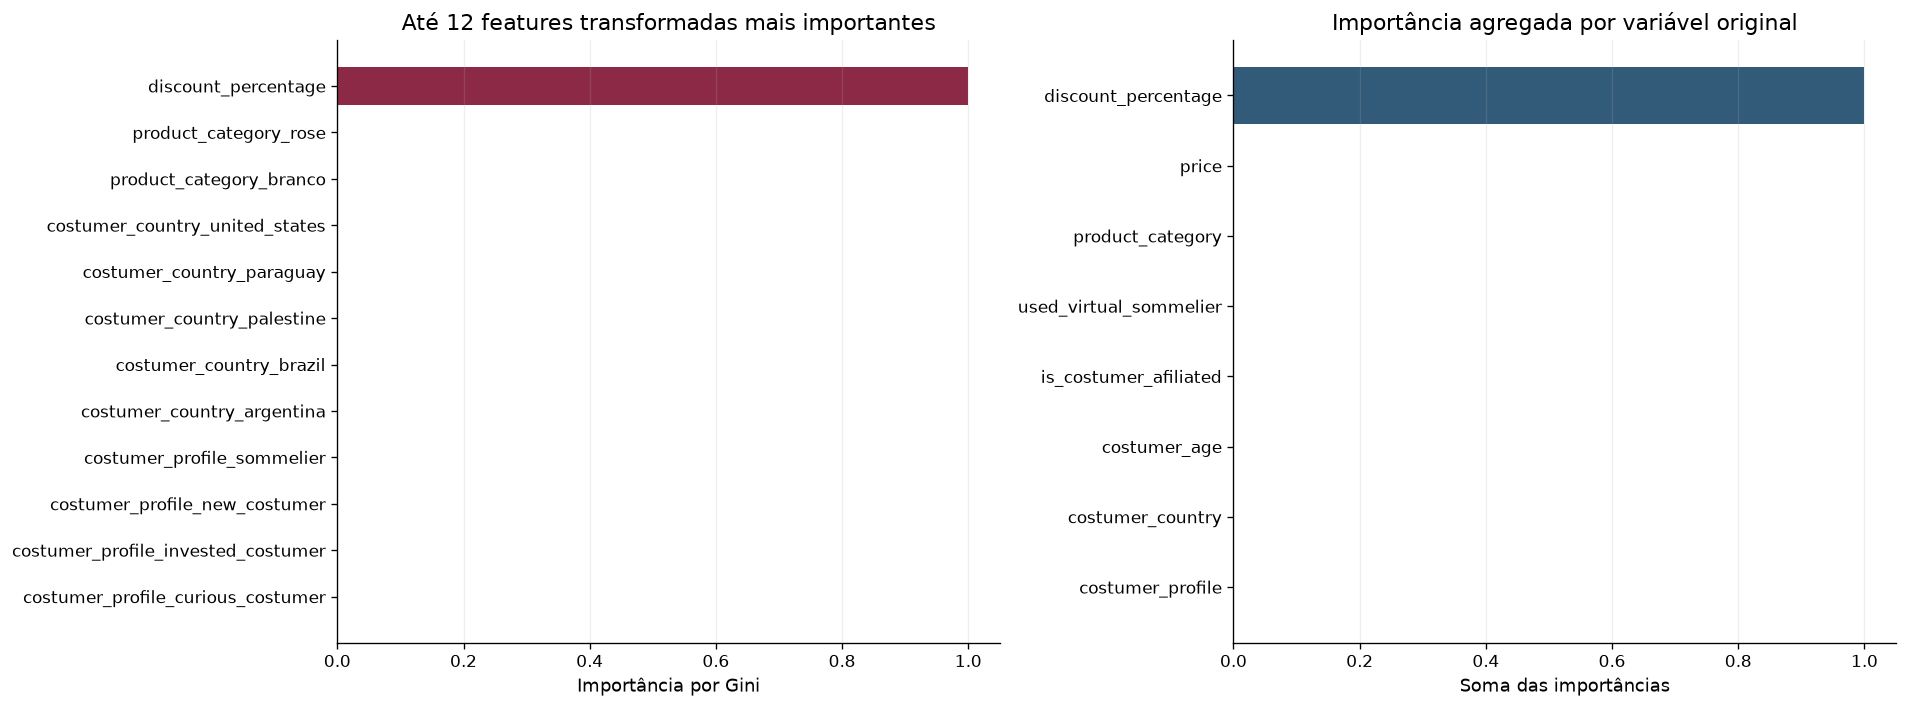

As maiores importâncias agregadas foram: `discount_percentage` (100.0%). Esses percentuais descrevem os cortes deste modelo, não efeitos causais na compra.

In [19]:
prep_ajustado = modelo_final.named_steps['preprocessamento']
arvore = modelo_final.named_steps['classificador']
nomes_transformados = prep_ajustado.get_feature_names_out()
encoder_ajustado = prep_ajustado.named_transformers_['nominais']
origens = [
    coluna
    for coluna, categorias in zip(CATEGORICAS, encoder_ajustado.categories_)
    for _ in categorias
] + NUMERICAS + BINARIAS
assert len(origens) == len(nomes_transformados) == len(arvore.feature_importances_)

importancias = pd.DataFrame({
    'Feature transformada': nomes_transformados,
    'Variável de origem': origens,
    'Importância': arvore.feature_importances_,
}).sort_values('Importância', ascending=False, kind='stable')
importancias_originais = (
    importancias.groupby('Variável de origem')['Importância'].sum()
    .reindex(FEATURES).sort_values(ascending=False, kind='stable')
)
display(importancias.reset_index(drop=True))
ranking_importancias = importancias_originais.rename('Importância agregada').to_frame()
ranking_importancias.insert(0, 'Posição (empates compartilham posição)',
                            importancias_originais.rank(ascending=False, method='min').astype(int))
display(ranking_importancias)
print('Cinco primeiras posições da tabela (zeros empatados seguem a ordem original):')
display(ranking_importancias.head(5))
display(Markdown(
    f'Quantidade de variáveis com importância positiva: **{int((importancias_originais > 0).sum())}**. '
    'Uma tabela com cinco linhas pode conter zeros empatados; não implica cinco '
    'features com contribuição efetiva. A ordem entre importâncias iguais não é informativa.'
))
importancia_sommelier = float(importancias_originais.loc['used_virtual_sommelier'])
posicao_sommelier = int(ranking_importancias.loc['used_virtual_sommelier'].iloc[0])
display(Markdown(
    f'**Sommelier Virtual:** importância agregada de {importancia_sommelier:.2%}; '
    f'posição {posicao_sommelier} entre {len(FEATURES)} variáveis, considerando empates. '
    'Importância zero significa ausência de cortes nesta árvore; uma importância positiva '
    'não comprova benefício, causalidade ou robustez fora da amostra.'
))

fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
top = importancias.head(12).sort_values('Importância')
rotulos = top['Feature transformada'].str.replace(
    r'^(nominais|numericas|binarias)__', '', regex=True,
)
eixos[0].barh(rotulos, top['Importância'], color=CORES[1])
eixos[0].set(title='Até 12 features transformadas mais importantes', xlabel='Importância por Gini')
agregadas = importancias_originais.sort_values()
eixos[1].barh(agregadas.index, agregadas.values, color=CORES[0])
eixos[1].set(title='Importância agregada por variável original', xlabel='Soma das importâncias')
for ax in eixos:
    ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

relevantes = importancias_originais[importancias_originais > 0]
texto_importancia = ', '.join(f'`{nome}` ({valor:.1%})' for nome, valor in relevantes.head(5).items())
display(Markdown(
    ('As maiores importâncias agregadas foram: ' + texto_importancia + '. '
     'Esses percentuais descrevem os cortes deste modelo, não efeitos causais na compra.')
    if len(relevantes) else
    'A árvore não realizou cortes; todas as importâncias são zero. Não há ranking informativo.'
))

### 18. Visualização gráfica da Árvore de Decisão

Cada nó mostra a feature e seu corte, Gini, número de amostras de treino (`samples`),
distribuição por classe (`value`, na ordem **[0, 1]**) e classe prevista.
Se houver pesos balanceados, `samples` continua sendo número de registros, mas
`value` representa contagens efetivas ponderadas, e não contagens brutas de pessoas. O ramo esquerdo
corresponde à condição verdadeira; o direito, à falsa. Em um indicador one-hot, um
corte em 0,5 separa ausência (0) e presença (1) da categoria.

Para manter a legibilidade, mostramos até a profundidade 3. Se a árvore final for
mais profunda, a figura é explicitamente parcial; nós com reticências têm ramos
não exibidos. As métricas sempre utilizam a árvore final inteira, sem truncamento
do modelo. Nomes curtos na figura são associados aos nomes exatos na tabela abaixo.

,Nome na figura,Feature exata
0,perfil = curious_costumer,nominais__costumer_profile_curious_costumer
1,perfil = invested_costumer,nominais__costumer_profile_invested_costumer
2,perfil = new_costumer,nominais__costumer_profile_new_costumer
3,perfil = sommelier,nominais__costumer_profile_sommelier
4,país = argentina,nominais__costumer_country_argentina
5,país = brazil,nominais__costumer_country_brazil
6,país = palestine,nominais__costumer_country_palestine
7,país = paraguay,nominais__costumer_country_paraguay
8,país = united_states,nominais__costumer_country_united_states
9,categoria = branco,nominais__product_category_branco


Profundidade real: 1; folhas: 2; nós: 3.
Visualização completa da árvore.


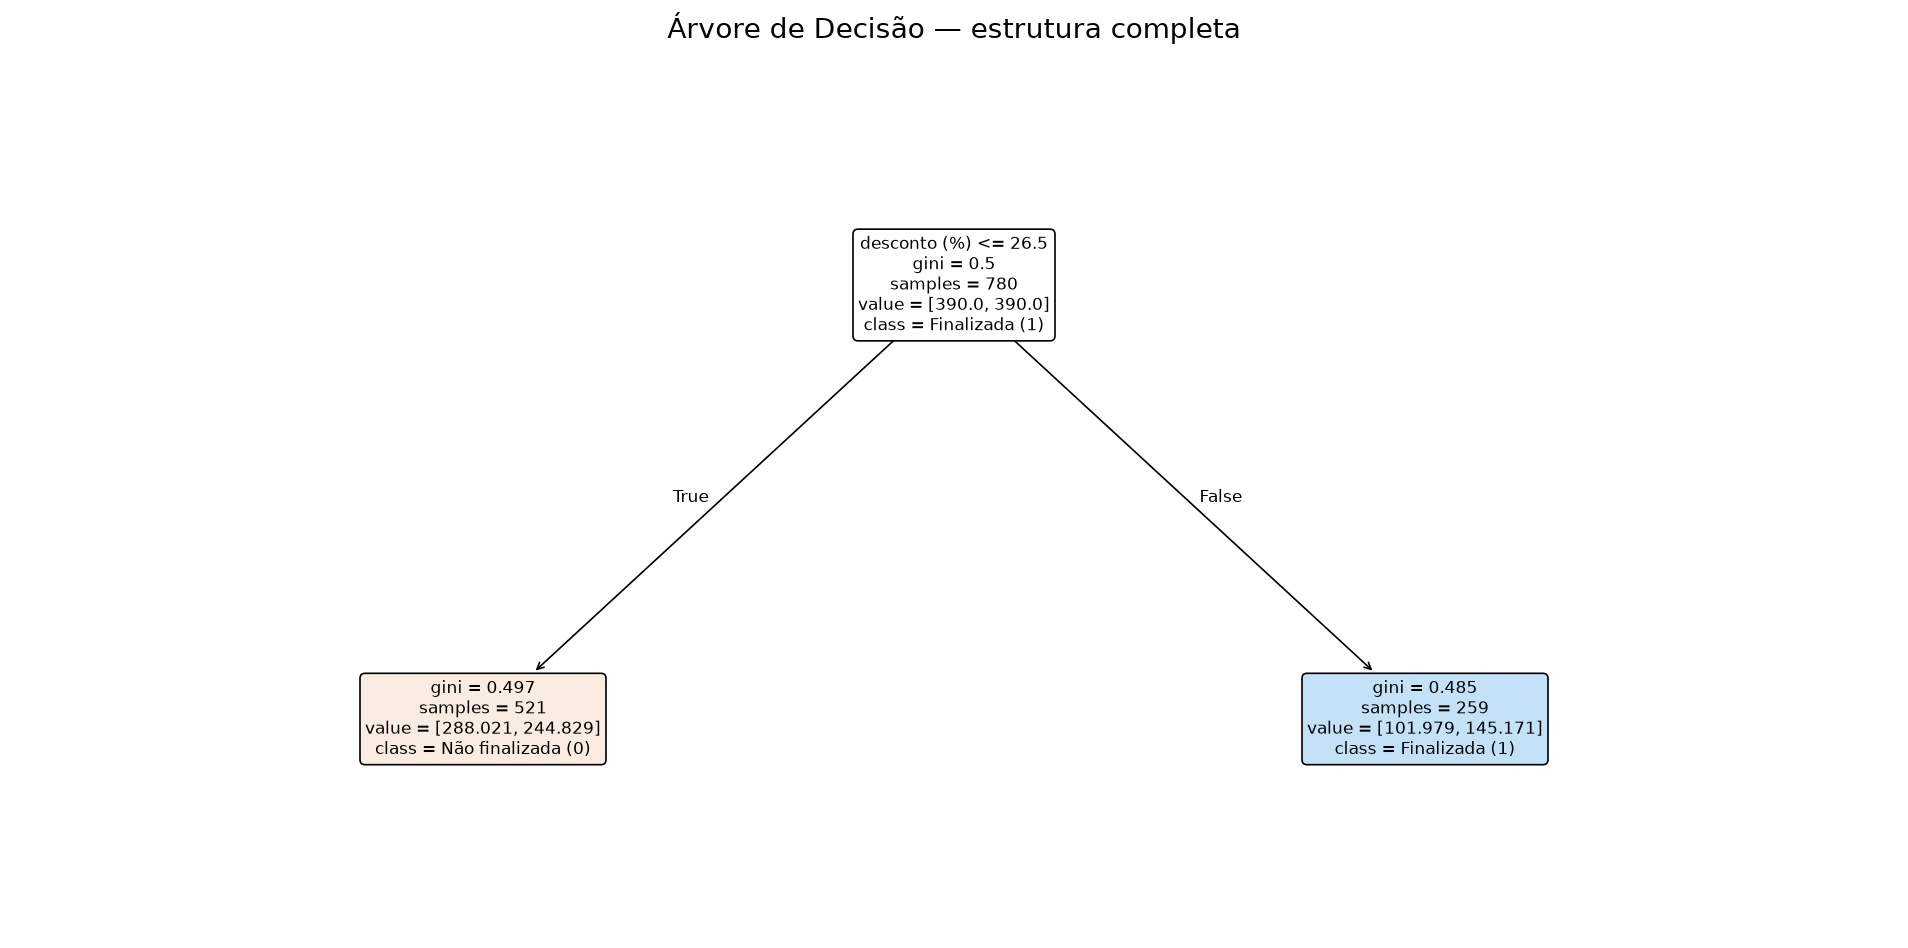

In [20]:
nomes_curtos = []
for nome in nomes_transformados:
    curto = nome.replace('nominais__costumer_profile_', 'perfil = ')
    curto = curto.replace('nominais__costumer_country_', 'país = ')
    curto = curto.replace('nominais__product_category_', 'categoria = ')
    curto = curto.replace('numericas__costumer_age', 'idade')
    curto = curto.replace('numericas__discount_percentage', 'desconto (%)')
    curto = curto.replace('numericas__price', 'preço')
    curto = curto.replace('binarias__is_costumer_afiliated', 'afiliado (0/1)')
    curto = curto.replace('binarias__used_virtual_sommelier', 'usou Sommelier (0/1)')
    nomes_curtos.append(curto)
display(pd.DataFrame({'Nome na figura': nomes_curtos, 'Feature exata': nomes_transformados}))
profundidade_real = arvore.get_depth()
profundidade_exibida = min(3, profundidade_real)
parcial = profundidade_real > profundidade_exibida
print(f'Profundidade real: {profundidade_real}; folhas: {arvore.get_n_leaves()}; '
      f'nós: {arvore.tree_.node_count}.')
print('Visualização parcial até a profundidade 3.' if parcial else 'Visualização completa da árvore.')

fig, ax = plt.subplots(figsize=(24, 11) if profundidade_exibida >= 3 else (16, 8))
plot_tree(
    arvore, feature_names=nomes_curtos, class_names=NOMES_CLASSES,
    max_depth=profundidade_exibida, filled=True, rounded=True,
    impurity=True, proportion=False, precision=3, fontsize=10, ax=ax,
)
ax.set_title(
    'Árvore de Decisão — ' + ('visualização parcial (profundidade ≤ 3)' if parcial else 'estrutura completa'),
    fontsize=17, pad=18,
)
fig.tight_layout()
plt.show()
plt.close(fig)

### 19. Análise de overfitting, underfitting e generalização

**Overfitting** ocorre quando o modelo aprende particularidades do treino que não
se sustentam em novas amostras. Uma diferença grande entre desempenho de ajuste e
validação é um indício. **Underfitting** ocorre quando as regras são simples demais
para capturar um padrão existente; desempenho baixo em ambos também pode decorrer
de falta de sinal nas features. Apenas esta comparação não distingue as duas causas.

Comparamos a árvore inicial, a selecionada e o Dummy nos mesmos folds internos.
O gráfico usa média de F1 macro e barras de desvio padrão entre folds, com divisor
igual ao número de folds (`ddof=0`), como no GridSearchCV. Não são intervalos de
confiança. A tabela inclui ainda o ajuste no treino completo e o
teste reservado, que usam conjuntos e tamanhos diferentes dos folds.

Capacidade de generalização exige desempenho em dados não usados no ajuste. Mesmo
um bom resultado neste teste seria restrito à simulação e aos IDs separados.

Não há regra universal que compare o gap de treino/validação com um desvio padrão
entre folds para concluir presença ou ausência de overfitting. Consideramos em
conjunto as diferenças observadas, a complexidade da árvore, a composição das
classes e a limitação de uma única amostra simulada, sem diagnóstico inferencial.


,F1 macro — ajuste nos folds,F1 macro — validação,Desvio entre folds de validação,F1 macro — treino completo,F1 macro — teste,Diferença ajuste folds − validação
Modelo,,,,,,
Dummy,0.3892,0.3892,0.0015,0.3892,0.3578,2.5683e-05
Árvore inicial,0.4811,0.4274,0.0335,0.4997,NaN,5.3646e-02
Árvore ajustada,0.5049,0.4964,0.0191,0.5047,0.4423,8.5286e-03


NaN na árvore inicial significa teste não avaliado, por decisão metodológica.


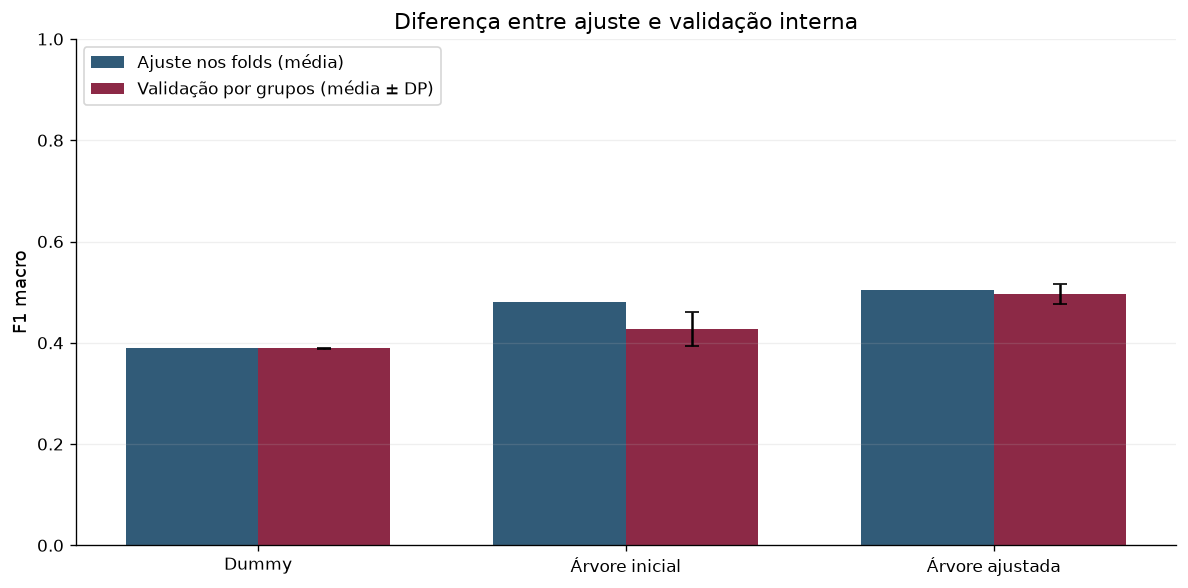

**Diagnóstico observado:** a árvore selecionada tem diferença de **0.85 p.p.** entre ajuste e validação interna em F1 macro, e de **6.24 p.p.** entre treino completo e teste. A árvore final tem profundidade 1 e 2 folhas. Os gaps são descritivos e não permitem atribuir toda a queda no teste a sobreajuste. Devem ser lidos junto à complexidade, à dispersão dos folds e à diferença de composição das classes. Não aplicamos um limiar gap/desvio padrão como teste de overfitting. A fraca discriminação também é compatível com baixo sinal nas features desta base simulada, sem provar ausência absoluta de relações. Resultados fracos não provam underfitting: também podem refletir pouco sinal preditivo na base simulada. Nenhum parâmetro será reajustado usando o teste.

In [21]:
linha_melhor = resultados_cv.iloc[indice_melhor]
resumo_generalizacao = pd.DataFrame([
    {
        'Modelo': 'Dummy',
        'F1 macro — ajuste nos folds': cv_baseline['train_f1_macro'].mean(),
        'F1 macro — validação': cv_baseline['test_f1_macro'].mean(),
        'Desvio entre folds de validação': cv_baseline['test_f1_macro'].std(ddof=0),
        'F1 macro — treino completo': f1_score(y_treino, baseline.predict(X_treino), average='macro'),
        'F1 macro — teste': metricas_dummy['F1 macro'],
    },
    {
        'Modelo': 'Árvore inicial',
        'F1 macro — ajuste nos folds': cv_inicial['train_f1_macro'].mean(),
        'F1 macro — validação': cv_inicial['test_f1_macro'].mean(),
        'Desvio entre folds de validação': cv_inicial['test_f1_macro'].std(ddof=0),
        'F1 macro — treino completo': f1_score(y_treino, modelo_inicial.predict(X_treino), average='macro'),
        'F1 macro — teste': np.nan,  # O teste não foi usado para comparar configurações.
    },
    {
        'Modelo': 'Árvore ajustada',
        'F1 macro — ajuste nos folds': linha_melhor['mean_train_f1_macro'],
        'F1 macro — validação': linha_melhor['mean_test_f1_macro'],
        'Desvio entre folds de validação': linha_melhor['std_test_f1_macro'],
        'F1 macro — treino completo': f1_score(y_treino, modelo_final.predict(X_treino), average='macro'),
        'F1 macro — teste': metricas_arvore['F1 macro'],
    },
]).set_index('Modelo')
resumo_generalizacao['Diferença ajuste folds − validação'] = (
    resumo_generalizacao['F1 macro — ajuste nos folds'] - resumo_generalizacao['F1 macro — validação']
)
display(resumo_generalizacao)
print('NaN na árvore inicial significa teste não avaliado, por decisão metodológica.')

fig, ax = plt.subplots(figsize=(10, 5))
posicoes = np.arange(len(resumo_generalizacao))
ax.bar(posicoes - 0.18, resumo_generalizacao['F1 macro — ajuste nos folds'],
       width=0.36, label='Ajuste nos folds (média)', color=CORES[0])
ax.bar(posicoes + 0.18, resumo_generalizacao['F1 macro — validação'],
       yerr=resumo_generalizacao['Desvio entre folds de validação'], capsize=4,
       width=0.36, label='Validação por grupos (média ± DP)', color=CORES[1])
ax.set_xticks(posicoes, resumo_generalizacao.index)
ax.set(title='Diferença entre ajuste e validação interna', ylabel='F1 macro', ylim=(0, 1))
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

gap_cv = float(linha_melhor['mean_train_f1_macro'] - linha_melhor['mean_test_f1_macro'])
gap_teste = float(resumo_generalizacao.loc['Árvore ajustada', 'F1 macro — treino completo']
                  - metricas_arvore['F1 macro'])
diagnostico_overfitting = (
    f'A árvore final tem profundidade {arvore.get_depth()} e '
    f'{arvore.get_n_leaves()} folhas. Os gaps são descritivos e não permitem '
    'atribuir toda a queda no teste a sobreajuste. Devem ser lidos junto à '
    'complexidade, à dispersão dos folds e à diferença de composição das classes. '
    'Não aplicamos um limiar gap/desvio padrão como teste de overfitting. '
    'A fraca discriminação também é compatível com baixo sinal nas features '
    'desta base simulada, sem provar ausência absoluta de relações. '
)
display(Markdown(
    f'**Diagnóstico observado:** a árvore selecionada tem diferença de '
    f'**{gap_cv * 100:.2f} p.p.** entre ajuste e validação interna em F1 macro, '
    f'e de **{gap_teste * 100:.2f} p.p.** entre treino completo e teste. '
    + diagnostico_overfitting
    + 'Resultados fracos não provam underfitting: também podem refletir pouco sinal '
      'preditivo na base simulada. Nenhum parâmetro será reajustado usando o teste.'
))

### 20. Gráficos adicionais: discriminação e detecção de não conclusão

A **curva ROC** usa compra finalizada (1) como positiva e varia o limiar sobre a
probabilidade estimada. ROC-AUC de 0,5 corresponde a ausência de discriminação na
referência aleatória; valores próximos desse patamar recomendam cautela.

A **curva Precision–Recall** abaixo trata **não finalização (0) como o evento de
interesse**, usando `1 − P(classe 1)`. Ela destaca o compromisso entre encontrar
mais tentativas não concluídas e gerar alertas corretos. A referência horizontal
é a prevalência da classe 0 no teste. AP (average precision) resume essa curva e
depende da prevalência; não é a precisão de um único limiar.

O Dummy produz uma probabilidade constante, sem ordenar riscos individuais. As
curvas são diagnósticos do teste e não serão usadas para escolher limiar ou modelo.
As probabilidades da árvore são frequências das folhas, sem garantia de calibração.

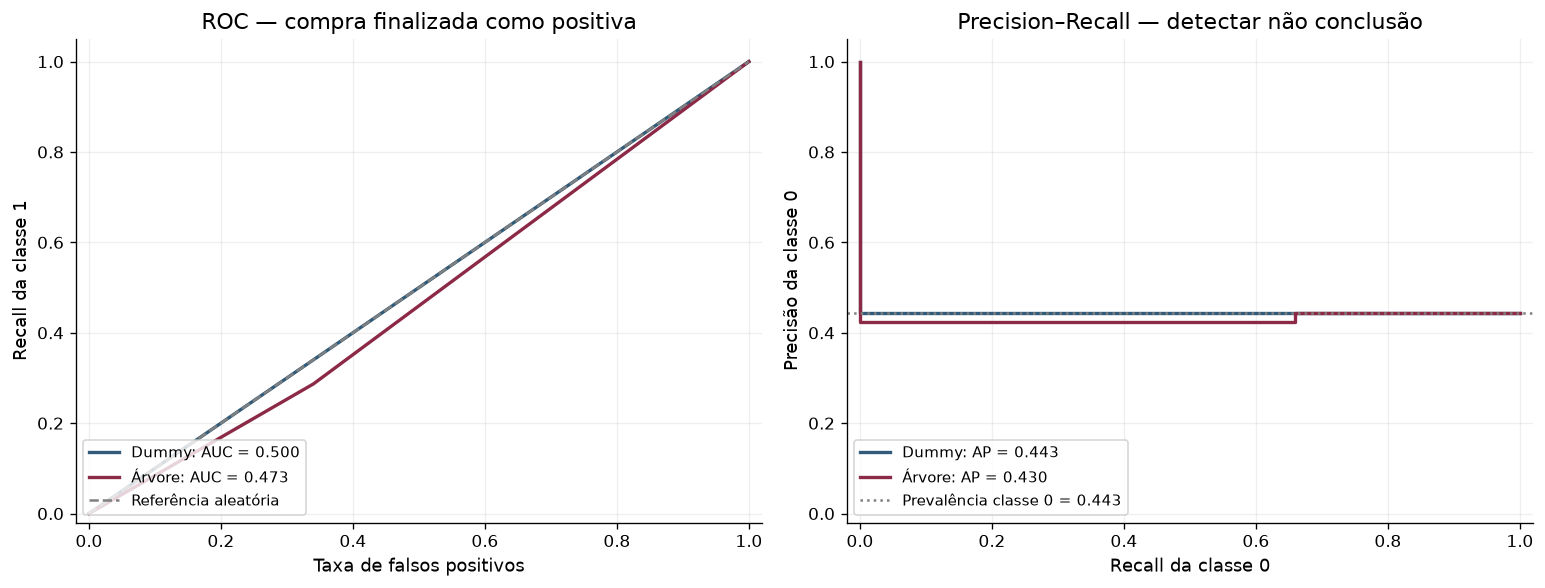

,ROC-AUC (positiva=1),AP (evento=0)
Modelo,,
Dummy,0.5000,0.4429
Árvore,0.4733,0.4303


A árvore obteve ROC-AUC = **0.4733** e AP para não conclusão = **0.4303**. A prevalência de não conclusão no teste é **44.29%**. Esses resultados descrevem a ordenação de risco nesta amostra e não demonstram calibração ou benefício econômico. A ROC-AUC ficou próxima de 0,5, indicando discriminação próxima da referência aleatória nesta amostra. O aumento de F1 macro sobre um classificador que ignora a classe 0 não deve ser confundido com forte poder preditivo.

In [22]:
y_teste_evento_0 = y_teste.eq(0).astype(int)
metricas_curvas = []
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for nome, probabilidades_1, cor in [
    ('Dummy', prob_dummy_1, CORES[0]), ('Árvore', prob_arvore_1, CORES[1]),
]:
    auc = roc_auc_score(y_teste, probabilidades_1)
    fpr, tpr, _ = roc_curve(y_teste, probabilidades_1, pos_label=1)
    eixos[0].plot(fpr, tpr, label=f'{nome}: AUC = {auc:.3f}', color=cor, linewidth=2)
    probabilidades_0 = 1 - probabilidades_1
    ap = average_precision_score(y_teste_evento_0, probabilidades_0)
    precisao, revocacao, _ = precision_recall_curve(y_teste_evento_0, probabilidades_0)
    eixos[1].step(revocacao, precisao, where='post',
                  label=f'{nome}: AP = {ap:.3f}', color=cor, linewidth=2)
    metricas_curvas.append({'Modelo': nome, 'ROC-AUC (positiva=1)': auc, 'AP (evento=0)': ap})
eixos[0].plot([0, 1], [0, 1], '--', color='gray', label='Referência aleatória')
eixos[0].set(title='ROC — compra finalizada como positiva',
             xlabel='Taxa de falsos positivos', ylabel='Recall da classe 1')
prevalencia_0_teste = float(y_teste_evento_0.mean())
eixos[1].axhline(prevalencia_0_teste, linestyle=':', color='gray',
                 label=f'Prevalência classe 0 = {prevalencia_0_teste:.3f}')
eixos[1].set(title='Precision–Recall — detectar não conclusão',
             xlabel='Recall da classe 0', ylabel='Precisão da classe 0')
for ax in eixos:
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9, loc='lower left')
fig.tight_layout()
plt.show()
plt.close(fig)
curvas = pd.DataFrame(metricas_curvas).set_index('Modelo')
display(curvas)
auc_arvore = float(curvas.loc['Árvore', 'ROC-AUC (positiva=1)'])
ap_arvore_0 = float(curvas.loc['Árvore', 'AP (evento=0)'])
diagnostico_discriminacao = (
    'A ROC-AUC ficou próxima de 0,5, indicando discriminação próxima da referência '
    'aleatória nesta amostra. O aumento de F1 macro sobre um classificador que '
    'ignora a classe 0 não deve ser confundido com forte poder preditivo.'
    if abs(auc_arvore - 0.5) < 0.05 else
    'A ROC-AUC deve ser interpretada com as demais métricas e replicada em dados '
    'externos; um ganho descritivo isolado não estabelece utilidade comercial.'
)
display(Markdown(
    f'A árvore obteve ROC-AUC = **{curvas.loc["Árvore", "ROC-AUC (positiva=1)"]:.4f}** '
    f'e AP para não conclusão = **{curvas.loc["Árvore", "AP (evento=0)"]:.4f}**. '
    f'A prevalência de não conclusão no teste é **{prevalencia_0_teste:.2%}**. '
    'Esses resultados descrevem a ordenação de risco nesta amostra e não demonstram '
    'calibração ou benefício econômico. ' + diagnostico_discriminacao
))

### 21. Interpretação dos resultados reais

A síntese abaixo é calculada com as saídas efetivas da execução. Responde às
questões de desempenho, importância, erros e aplicação sem substituir os números
por uma expectativa de sucesso. A interpretação considera a base simulada,
a separação por ID e a ausência de uma validação externa.

In [23]:
erro_mais_frequente = (
    f'falsos positivos ({fp}), isto é, prever conclusão em tentativas que não concluíram'
    if fp > fn else
    f'falsos negativos ({fn}), isto é, prever não conclusão em tentativas que concluíram'
    if fn > fp else f'ambos os tipos de erro, com {fp} ocorrências cada'
)
interpretacao = f'''
**1. O modelo superou o baseline?** {leitura_baseline}
A árvore alcançou acurácia de {metricas_arvore['Accuracy']:.2%}, contra
{metricas_dummy['Accuracy']:.2%} do Dummy; F1 macro de
{metricas_arvore['F1 macro']:.4f}, contra {metricas_dummy['F1 macro']:.4f}; e
balanced accuracy de {metricas_arvore['Balanced Accuracy']:.4f}, contra
{metricas_dummy['Balanced Accuracy']:.4f}. A comparação deve considerar todas essas
métricas, não apenas a taxa total de acertos.
A ROC-AUC foi {auc_arvore:.4f}; a AP para não conclusão foi {ap_arvore_0:.4f},
comparada à prevalência de {prevalencia_0_teste:.4f}. {diagnostico_discriminacao}

**2. Identifica compras finalizadas?** Precisão de
{metricas_arvore['Precision (classe 1)']:.2%}, recall de
{metricas_arvore['Recall (classe 1)']:.2%} e F1 de
{metricas_arvore['F1 (classe 1)']:.4f}. Foram reconhecidas {tp} das {tp + fn}
conclusões reais; {fn} não foram reconhecidas. Essas métricas quantificam diretamente
os acertos e erros na classe 1 e devem ser lidas junto das métricas da classe 0.

**3. Identifica compras não finalizadas?** Precisão de
{metricas_arvore['Precision (classe 0)']:.2%}, recall de
{metricas_arvore['Recall (classe 0)']:.2%} e F1 de
{metricas_arvore['F1 (classe 0)']:.4f}. Foram detectadas {tn} das {tn + fp}
não conclusões; {fp} passaram como previsão de conclusão. A detecção de risco deve
ser julgada diretamente por esses números, não pela acurácia global.
O modelo deixou de identificar {fp / (tn + fp):.2%} das não conclusões reais.

**4. Quais features foram relevantes?** Há {len(relevantes)} variável(is) com importância
positiva nesta árvore: {texto_importancia if len(relevantes) else 'nenhuma, pois não houve cortes'}.
A tabela de cinco primeiras posições está na seção 17; quando houver menos de cinco
importâncias positivas, as demais linhas são zeros empatados e não indicam contribuição.
Neste modelo, importância é uma medida relativa de uso nos cortes, não qualidade de previsão.
Isso descreve a redução de impureza no treino. Não comprova que mudar idade, perfil,
preço ou desconto alteraria a probabilidade de compra, nem confirma robustez em
outros produtos ou amostras.
O indicador `used_virtual_sommelier` teve importância {importancia_sommelier:.2%} e
posição {posicao_sommelier} no ranking com empates. Sua inclusão/exclusão no treino,
com os mesmos hiperparâmetros, variou o F1 macro em {impacto_sommelier_cv * 100:+.2f}
p.p. (com − sem). Essa ablação não é uma busca independente de hiperparâmetros
para o modelo sem Sommelier, e o modelo com Sommelier foi selecionado na mesma
validação. Portanto, não é evidência estatística ou causal de benefício.
As taxas exploratórias de conclusão foram {taxa_sommelier_com:.2%} com uso e
{taxa_sommelier_sem:.2%} sem uso; a diferença foi {diferenca_taxa_sommelier * 100:+.2f}
p.p. Não existe associação positiva evidente nessa comparação agregada.

**5. Quais erros predominam?** Predominam {erro_mais_frequente}.
Um falso positivo representa risco não sinalizado; um falso negativo pode gerar
atendimento ou incentivo desnecessário. Sem custos documentados, não é possível
calcular o impacto financeiro ou decidir qual erro deve receber maior penalidade.

**6. Há sinais de sobreajuste?** A diferença ajuste–validação em F1 macro é
{gap_cv * 100:.2f} p.p.; a diferença treino completo–teste é
{gap_teste * 100:.2f} p.p. A árvore final tem profundidade {profundidade_real} e
{arvore.get_n_leaves()} folhas: foi a melhor configuração desta grade por F1 macro,
o que não significa que seja uma solução comercial adequada ou ótima em geral.
{diagnostico_overfitting} Os valores e a variação entre folds são apresentados
na seção 19. A escolha entre configurações também
torna a melhor média de validação otimista. Desempenho fraco fora do treino pode
indicar sobreajuste e/ou pouco sinal nas features, sem demonstrar sozinho underfitting.

**7. Há utilidade prática neste estado?** O artefato é útil para demonstrar um
processo de modelagem e suas limitações. Não há sustentação para automatizar
campanhas, descontos ou decisões sobre clientes reais com esta única experiência:
faltam dados reais consistentes, avaliação externa, custos de erro e evidência de
benefício comercial. Ganhos descritivos, quando presentes, precisam ser replicados.
'''
display(Markdown(interpretacao))


**1. O modelo superou o baseline?** A árvore não supera simultaneamente o Dummy em F1 macro e balanced accuracy neste teste. Não há melhora consistente nessas duas métricas para justificar seu uso comercial a partir deste experimento.
A árvore alcançou acurácia de 45.21%, contra
55.71% do Dummy; F1 macro de
0.4423, contra 0.3578; e
balanced accuracy de 0.4733, contra
0.5000. A comparação deve considerar todas essas
métricas, não apenas a taxa total de acertos.
A ROC-AUC foi 0.4733; a AP para não conclusão foi 0.4303,
comparada à prevalência de 0.4429. A ROC-AUC ficou próxima de 0,5, indicando discriminação próxima da referência aleatória nesta amostra. O aumento de F1 macro sobre um classificador que ignora a classe 0 não deve ser confundido com forte poder preditivo.

**2. Identifica compras finalizadas?** Precisão de
51.47%, recall de
28.69% e F1 de
0.3684. Foram reconhecidas 35 das 122
conclusões reais; 87 não foram reconhecidas. Essas métricas quantificam diretamente
os acertos e erros na classe 1 e devem ser lidas junto das métricas da classe 0.

**3. Identifica compras não finalizadas?** Precisão de
42.38%, recall de
65.98% e F1 de
0.5161. Foram detectadas 64 das 97
não conclusões; 33 passaram como previsão de conclusão. A detecção de risco deve
ser julgada diretamente por esses números, não pela acurácia global.
O modelo deixou de identificar 34.02% das não conclusões reais.

**4. Quais features foram relevantes?** Há 1 variável(is) com importância
positiva nesta árvore: `discount_percentage` (100.0%).
A tabela de cinco primeiras posições está na seção 17; quando houver menos de cinco
importâncias positivas, as demais linhas são zeros empatados e não indicam contribuição.
Neste modelo, importância é uma medida relativa de uso nos cortes, não qualidade de previsão.
Isso descreve a redução de impureza no treino. Não comprova que mudar idade, perfil,
preço ou desconto alteraria a probabilidade de compra, nem confirma robustez em
outros produtos ou amostras.
O indicador `used_virtual_sommelier` teve importância 0.00% e
posição 2 no ranking com empates. Sua inclusão/exclusão no treino,
com os mesmos hiperparâmetros, variou o F1 macro em +0.00
p.p. (com − sem). Essa ablação não é uma busca independente de hiperparâmetros
para o modelo sem Sommelier, e o modelo com Sommelier foi selecionado na mesma
validação. Portanto, não é evidência estatística ou causal de benefício.
As taxas exploratórias de conclusão foram 61.68% com uso e
62.17% sem uso; a diferença foi -0.49
p.p. Não existe associação positiva evidente nessa comparação agregada.

**5. Quais erros predominam?** Predominam falsos negativos (87), isto é, prever não conclusão em tentativas que concluíram.
Um falso positivo representa risco não sinalizado; um falso negativo pode gerar
atendimento ou incentivo desnecessário. Sem custos documentados, não é possível
calcular o impacto financeiro ou decidir qual erro deve receber maior penalidade.

**6. Há sinais de sobreajuste?** A diferença ajuste–validação em F1 macro é
0.85 p.p.; a diferença treino completo–teste é
6.24 p.p. A árvore final tem profundidade 1 e
2 folhas: foi a melhor configuração desta grade por F1 macro,
o que não significa que seja uma solução comercial adequada ou ótima em geral.
A árvore final tem profundidade 1 e 2 folhas. Os gaps são descritivos e não permitem atribuir toda a queda no teste a sobreajuste. Devem ser lidos junto à complexidade, à dispersão dos folds e à diferença de composição das classes. Não aplicamos um limiar gap/desvio padrão como teste de overfitting. A fraca discriminação também é compatível com baixo sinal nas features desta base simulada, sem provar ausência absoluta de relações.  Os valores e a variação entre folds são apresentados
na seção 19. A escolha entre configurações também
torna a melhor média de validação otimista. Desempenho fraco fora do treino pode
indicar sobreajuste e/ou pouco sinal nas features, sem demonstrar sozinho underfitting.

**7. Há utilidade prática neste estado?** O artefato é útil para demonstrar um
processo de modelagem e suas limitações. Não há sustentação para automatizar
campanhas, descontos ou decisões sobre clientes reais com esta única experiência:
faltam dados reais consistentes, avaliação externa, custos de erro e evidência de
benefício comercial. Ganhos descritivos, quando presentes, precisam ser replicados.


### 22. Insights e possíveis aplicações para a Vinheria

O principal aprendizado comercial é a necessidade de **medir a não conclusão
diretamente**. A proporção global de compras finalizadas permite a um modelo trivial
obter cerca de 62% de acurácia, mesmo sem detectar risco. Uma futura solução do
Sommelier Virtual deveria acompanhar recall e precisão dos alertas, além da taxa
de conclusão e do custo de atendimento.

Perfis, países e categorias podem apoiar hipóteses de segmentação, mas a importância
observada na árvore não valida campanhas para um segmento. Categorias pequenas e
cadastros inconsistentes limitam comparações. A árvore também não estabelece que
descontos aumentem conversão: decisões sobre campanhas e preço exigem dados melhores
e, idealmente, avaliação experimental de uma intervenção.

Para planejamento comercial, o notebook fornece um protocolo de avaliação e um
inventário de lacunas de dados. A aplicação futura mais plausível é testar um
**sinal de risco para apoiar atendimento**, com supervisão e validação prospectiva,
e não tratar as previsões simuladas como uma política de vendas já comprovada.
O resumo abaixo explicita o desempenho real que limita essa hipótese.

O uso do Sommelier Virtual está agora representado por um indicador binário, mas
suas taxas agregadas de conclusão são quase iguais. Os dados não permitem afirmar
que a funcionalidade aumente vendas. Um piloto real precisaria registrar o momento
da interação, o contexto da recomendação e o resultado posterior; um experimento
controlado seria necessário para avaliar efeito causal.


In [24]:
display(Markdown(
    f'Neste teste, a árvore sinalizou **{int((pred_arvore == 0).sum())} tentativas** '
    f'como não conclusão; **{tn}** eram não conclusões reais e **{fn}** concluíram. '
    f'Além disso, **{fp} não conclusões reais não foram sinalizadas**. '
    'Esse volume de acertos e erros é a referência observada para discutir '
    'um possível piloto, sem estimar receita recuperada ou retorno não medidos.'
))

Neste teste, a árvore sinalizou **151 tentativas** como não conclusão; **64** eram não conclusões reais e **87** concluíram. Além disso, **33 não conclusões reais não foram sinalizadas**. Esse volume de acertos e erros é a referência observada para discutir um possível piloto, sem estimar receita recuperada ou retorno não medidos.

### 23. Limitações do estudo

1. **Base simulada:** os padrões observados podem não representar comportamento real.
2. **Inconsistências cadastrais:** IDs, idades e definição de novo cliente não
   sustentam uma interpretação confiável de histórico individual.
3. **Catálogo reduzido:** oito produtos, com atributos fixos e preço identificando
   cada produto nesta amostra. Não avaliamos generalização a produtos inéditos.
4. **Sinal preditivo limitado:** os resultados devem mostrar se as oito features
   permitem discriminação útil. Importâncias internas não equivalem a comprovação
   de muitas features realmente preditivas fora da amostra.
5. **Variáveis ausentes:** existe apenas um indicador de uso do Sommelier, sem
   timestamps, intensidade ou conteúdo das interações. Não há navegação, carrinho, canal ou outras
   informações que poderiam explicar melhor a conclusão.
6. **Cronologia incompleta:** há datas futuras simuladas e não há timestamp de
   disponibilidade de cada atributo; assumimos cadastro e oferta anteriores à decisão.
7. **Avaliação limitada:** um único holdout por grupos e cinco folds internos;
   não realizamos validação externa ou estimativa formal de significância dos ganhos.
8. **Ajuste por seleção:** testamos várias configurações; o melhor score de validação
   tende a ser otimista. O teste não foi utilizado para escolher outra configuração.
9. **Probabilidades e custos:** não avaliamos calibração, benefício financeiro ou
   efeito causal de campanhas; mantivemos a decisão padrão do classificador.
10. **Sem garantia de generalização:** nenhuma métrica aqui comprova desempenho
    em clientes reais, novas épocas, outro catálogo ou canais de venda.

A tabela reapresenta somente indicadores já calculados, para contextualizar o
alcance da avaliação.

11. **Sorteios na referência XLSX:** as fórmulas consultadas geram uso do Sommelier
    e alvo por sorteios separados; não representam comportamento de usuários reais.
    O XLSX não fornece uma fotografia idêntica ao CSV. Não se deve confundir essa
    referência com evidência de uma relação de negócio aprendível no CSV atual.
12. **Disponibilidade do Sommelier:** o indicador só é metodologicamente utilizável
    se o uso tiver ocorrido antes do corte de previsão; essa condição não é
    verificável nesta base, restringindo a análise a um cenário exploratório.


In [25]:
display(pd.Series({
    'Registros da simulação': len(df),
    'Produtos observados': df['product_id'].nunique(),
    'Features originais utilizadas': len(FEATURES),
    'IDs no teste': g_teste.nunique(),
    'Registros no teste': len(y_teste),
    'Folds internos de validação': len(FOLDS),
    'Configurações avaliadas no treino': len(resultados_cv),
}, name='Escopo observado').to_frame())

,Escopo observado
Registros da simulação,999
Produtos observados,8
Features originais utilizadas,8
IDs no teste,36
Registros no teste,219
Folds internos de validação,5
Configurações avaliadas no treino,90


### 24. Melhorias futuras

Uma próxima fase deveria começar pela coleta e documentação de dados reais, com
identificador de tentativa/carrinho, chave de cliente estável, definição de não
conclusão e janela de observação para que uma tentativa ainda aberta não seja
rotulada prematuramente como abandonada.

| Melhoria | Possível contribuição e cuidado temporal |
|---|---|
| Navegação e quantidade de produtos visualizados | Medir interesse até o instante da previsão. |
| Interação com o Sommelier Virtual | Enriquecer o indicador existente com timestamps, número e conteúdo de interações anteriores ao corte. |
| Carrinho e sinais de abandono | Usar conteúdo e inatividade anteriores ao corte; não usar o abandono futuro que define o alvo. |
| Histórico de compras | Calcular frequência, recência e valor somente com eventos anteriores. |
| Tempo de sessão | Utilizar tempo transcorrido até o corte, sem incluir a duração final futura. |
| Método de pagamento | Usar apenas se já selecionado antes da previsão; resultado do pagamento pode revelar o alvo. |
| Região e canal de venda | Representar contexto comercial, respeitando disponibilidade e finalidade dos dados. |
| Validação temporal | Treinar em períodos anteriores e testar em posteriores, com definição explícita para clientes recorrentes. |
| Comparação de algoritmos | Comparar Logistic Regression, Random Forest e KNN com o mesmo protocolo; KNN e regressão podem exigir escalonamento. |
| Calibração e limiares | Avaliar dentro do treino/validação e com custos definidos, preservando teste final. |

Não implementamos outros modelos nesta etapa além do Dummy de referência e da
Árvore de Decisão. A prioridade é melhorar a fonte e demonstrar benefício fora
da amostra, antes de aumentar a complexidade do algoritmo.

In [26]:
# Integridade do procedimento, sem gerar arquivos auxiliares na entrega.
assert X.columns.tolist() == FEATURES
assert set(g_treino).isdisjoint(g_teste)
assert arvore.tree_.n_node_samples[0] == len(X_treino)
for coluna, categorias in zip(CATEGORICAS, encoder_ajustado.categories_):
    assert set(categorias) == set(X_treino[coluna].unique())
assert sha256(CSV_PATH.read_bytes()).hexdigest() == HASH_ORIGINAL
print('Verificações aprovadas: oito features, grupos separados, encoder ajustado no treino,')
print('árvore final ajustada no treino completo e CSV original com hash preservado.')

Verificações aprovadas: oito features, grupos separados, encoder ajustado no treino,
árvore final ajustada no treino completo e CSV original com hash preservado.


### 25. Conclusão e revisão metodológica frente às referências

O enunciado requer classificação supervisionada, explicação dos atributos,
separação treino/teste e métricas de avaliação, em uma base simulada com pelo menos
oito colunas e resultado da venda. As notas do grupo acrescentam compreensão do
CSV, codificação apropriada, métricas e gráficos, importância das features,
justificativa e visualização da árvore, com Markdown entre etapas de código.

| Requisito | Evidência neste notebook |
|---|---|
| Fonte CSV e base com pelo menos oito colunas e alvo | Seções 3–4: 999 registros, 16 colunas e alvo binário. |
| Entendimento dos atributos e qualidade | Seções 3–5 e 7–8: tipos, exemplos, ausências, duplicados, hipóteses e limitações. |
| Algoritmo supervisionado e justificativa | Seções 11–13: Árvore de Decisão e controle de complexidade. |
| Atributos escolhidos e excluídos | Seção 7: oito features e justificativas individuais. |
| Codificação nominal sem hierarquia artificial | Seções 8–9: OneHotEncoder e dois indicadores binários. |
| Lógica treino/teste e prevenção de leakage | Seções 9–10, 13 e 13.2: Pipeline, auditoria de grupos, distribuições e estabilidade interna sem substituir o teste. |
| Acurácia, precisão e métricas adicionais | Seções 14–16 e 20: métricas por classe, macro, balanceada, matriz e curvas. |
| Baseline e reflexão crítica de desempenho | Seções 6, 15, 19 e 21: Dummy, generalização e interpretação dos números reais. |
| Importância/peso das variáveis | Seção 17: nomes pós-encoder, tabela, agregação e gráfico. |
| Visualização gráfica da árvore | Seção 18: cortes, Gini, amostras, classes e previsão, com aviso de profundidade. |
| Sommelier Virtual e fonte atual | Seções 3, 5.1, 7–8, 13.1, 17 e 21: fonte oficial, temporalidade, associação, ablação e importância sem causalidade. |
| Relatório executável com Markdown e código | Células explicativas intercaladas com código e resultados salvos. |
| Reflexão sobre insights e desempenho | Seções 21–25, sem inferência causal indevida. |
| PDF, dashboard e screenshots da entrega completa | Fora deste arquivo; não foram criados ou alterados nesta etapa. |

A conclusão abaixo utiliza os resultados reais. Um modelo com baixa discriminação
continua sendo um resultado acadêmico válido quando o processo é transparente e
as limitações são reconhecidas.

#### Significado acadêmico do desempenho observado

Baixo desempenho **não representa falha na execução do trabalho**. O protocolo
correto pode demonstrar que as features disponíveis têm baixo poder preditivo
para o target desta amostra simulada. Modelos supervisionados não conseguem criar
sinal preditivo generalizável que não existe nos dados; aumentar a complexidade
pode apenas memorizar ruído. Os resultados não provam ausência absoluta de qualquer
relação, mas não sustentam previsão comercial útil com estas entradas e avaliação.

Uma aplicação real exigiria dados comportamentais e comerciais mais ricos e
confiáveis: navegação e tempo de sessão até o corte, interação com o Sommelier,
conteúdo do carrinho, histórico anterior, canal, oferta e condições de pagamento,
sempre respeitando disponibilidade temporal e uma validação externa apropriada.
O teste foi mantido, inclusive quando a árvore não supera consistentemente o Dummy.


In [27]:
conclusao = f'''
O objetivo foi prever se uma tentativa de compra da Vinheria Agnello seria finalizada,
por meio de uma Árvore de Decisão supervisionada. A análise utilizou 999 registros
simulados, oito atributos de cadastro, oferta e uso do Sommelier, codificação nominal com OneHotEncoder
e dois indicadores binários. A divisão reservou {len(y_teste)} registros para teste
({len(y_teste) / len(df):.2%}), com {g_teste.nunique()} IDs exclusivos e nenhum ID
compartilhado com o treino. O ajuste de complexidade ocorreu em cinco folds internos
por grupos, escolhendo F1 macro entre {len(resultados_cv)} configurações.

A árvore selecionada utilizou `{busca.best_params_}`. No teste, obteve
**acurácia de {metricas_arvore['Accuracy']:.2%}**, **F1 macro de
{metricas_arvore['F1 macro']:.4f}** e **balanced accuracy de
{metricas_arvore['Balanced Accuracy']:.4f}**. Seu recall para compras não finalizadas
foi **{metricas_arvore['Recall (classe 0)']:.2%}**. O baseline obteve acurácia de
{metricas_dummy['Accuracy']:.2%}, F1 macro de {metricas_dummy['F1 macro']:.4f} e
balanced accuracy de {metricas_dummy['Balanced Accuracy']:.4f}.
{leitura_baseline}
Contudo, a ROC-AUC foi {auc_arvore:.4f}, a AP para não conclusão foi
{ap_arvore_0:.4f} e a prevalência dessa classe foi {prevalencia_0_teste:.4f}.
{diagnostico_discriminacao}

Os principais aprendizados foram a insuficiência da acurácia isolada, a necessidade
de separar tentativas por cliente, a importância de respeitar o momento da previsão
e a distinção entre importância preditiva e causalidade. As inconsistências
cadastrais, o catálogo de oito produtos, a simulação e a ausência de comportamento
real e de timestamps das interações restringem a interpretação. A diferença de F1 macro entre ajuste
e validação foi de {gap_cv * 100:.2f} p.p., e o teste não foi usado para reajustar
o modelo. {diagnostico_overfitting}

A importância do indicador `used_virtual_sommelier` foi de
{importancia_sommelier:.2%} (posição {posicao_sommelier}, com empates). A diferença
exploratória de conclusão entre uso e não uso foi {diferenca_taxa_sommelier * 100:+.2f}
p.p.; não há evidência de influência positiva a partir dessa comparação.
A ablação com hiperparâmetros fixos variou o F1 macro de validação em
{impacto_sommelier_cv * 100:+.2f} p.p. (com − sem). Esses números não demonstram
efeito causal ou benefício comercial.

A fonte exclusiva foi `01_Dados/dataset_vinheria_agnello.csv`, SHA-256
`{HASH_ORIGINAL}`. O XLSX foi apenas inspecionado, sem recalcular fórmulas.

Baixo desempenho não caracteriza falha de execução: as features disponíveis
mostraram baixo poder preditivo para o alvo desta base simulada. Modelos
supervisionados não criam sinal generalizável ausente nos dados; mais complexidade
pode apenas ajustar ruído. Dados comportamentais e comerciais mais ricos são
necessários para uma aplicação real.

O notebook atende à etapa metodológica e serve como base explicativa para o PDF
acadêmico. Uma aplicação futura ao Sommelier Virtual ou à identificação de risco
de não conclusão requer dados reais consistentes, validação temporal/externa,
análise de custos e evidência de benefício comercial. **O CSV original foi preservado.**
'''
display(Markdown(conclusao))
print('Revisão concluída frente a ENUNCIADO_FASE3.txt e NOTAS_FELIPE.txt.')
print('Notebook atualizado com resultados atuais. CSV e XLSX oficiais preservados diretamente em 01_Dados.')


O objetivo foi prever se uma tentativa de compra da Vinheria Agnello seria finalizada,
por meio de uma Árvore de Decisão supervisionada. A análise utilizou 999 registros
simulados, oito atributos de cadastro, oferta e uso do Sommelier, codificação nominal com OneHotEncoder
e dois indicadores binários. A divisão reservou 219 registros para teste
(21.92%), com 36 IDs exclusivos e nenhum ID
compartilhado com o treino. O ajuste de complexidade ocorreu em cinco folds internos
por grupos, escolhendo F1 macro entre 90 configurações.

A árvore selecionada utilizou `{'classificador__class_weight': 'balanced', 'classificador__max_depth': 1, 'classificador__min_samples_leaf': 10, 'classificador__min_samples_split': 2}`. No teste, obteve
**acurácia de 45.21%**, **F1 macro de
0.4423** e **balanced accuracy de
0.4733**. Seu recall para compras não finalizadas
foi **65.98%**. O baseline obteve acurácia de
55.71%, F1 macro de 0.3578 e
balanced accuracy de 0.5000.
A árvore não supera simultaneamente o Dummy em F1 macro e balanced accuracy neste teste. Não há melhora consistente nessas duas métricas para justificar seu uso comercial a partir deste experimento.
Contudo, a ROC-AUC foi 0.4733, a AP para não conclusão foi
0.4303 e a prevalência dessa classe foi 0.4429.
A ROC-AUC ficou próxima de 0,5, indicando discriminação próxima da referência aleatória nesta amostra. O aumento de F1 macro sobre um classificador que ignora a classe 0 não deve ser confundido com forte poder preditivo.

Os principais aprendizados foram a insuficiência da acurácia isolada, a necessidade
de separar tentativas por cliente, a importância de respeitar o momento da previsão
e a distinção entre importância preditiva e causalidade. As inconsistências
cadastrais, o catálogo de oito produtos, a simulação e a ausência de comportamento
real e de timestamps das interações restringem a interpretação. A diferença de F1 macro entre ajuste
e validação foi de 0.85 p.p., e o teste não foi usado para reajustar
o modelo. A árvore final tem profundidade 1 e 2 folhas. Os gaps são descritivos e não permitem atribuir toda a queda no teste a sobreajuste. Devem ser lidos junto à complexidade, à dispersão dos folds e à diferença de composição das classes. Não aplicamos um limiar gap/desvio padrão como teste de overfitting. A fraca discriminação também é compatível com baixo sinal nas features desta base simulada, sem provar ausência absoluta de relações. 

A importância do indicador `used_virtual_sommelier` foi de
0.00% (posição 2, com empates). A diferença
exploratória de conclusão entre uso e não uso foi -0.49
p.p.; não há evidência de influência positiva a partir dessa comparação.
A ablação com hiperparâmetros fixos variou o F1 macro de validação em
+0.00 p.p. (com − sem). Esses números não demonstram
efeito causal ou benefício comercial.

A fonte exclusiva foi `01_Dados/dataset_vinheria_agnello.csv`, SHA-256
`39897f7a1648eed5bb3a58b36a5a131dd67fdf96a190596f36a8ee14bf91a4e1`. O XLSX foi apenas inspecionado, sem recalcular fórmulas.

Baixo desempenho não caracteriza falha de execução: as features disponíveis
mostraram baixo poder preditivo para o alvo desta base simulada. Modelos
supervisionados não criam sinal generalizável ausente nos dados; mais complexidade
pode apenas ajustar ruído. Dados comportamentais e comerciais mais ricos são
necessários para uma aplicação real.

O notebook atende à etapa metodológica e serve como base explicativa para o PDF
acadêmico. Uma aplicação futura ao Sommelier Virtual ou à identificação de risco
de não conclusão requer dados reais consistentes, validação temporal/externa,
análise de custos e evidência de benefício comercial. **O CSV original foi preservado.**


Revisão concluída frente a ENUNCIADO_FASE3.txt e NOTAS_FELIPE.txt.
Notebook atualizado com resultados atuais. CSV e XLSX oficiais preservados diretamente em 01_Dados.
